# Part 1 - Frozen MedDINOv3 feature extraction (OrganMNIST3D, 3 anatomical views)

Faithful-reproduction setup for *Axial-Centric Cross-Plane Attention* (Park, Kim, Baskaran):
64x64x64 volumes -> axial / coronal / sagittal slices (64 each) -> 224x224, gray duplicated to the model's channels -> **frozen official MedDINOv3 ViT-B/16** -> `[N, 64, E]` per view.

**Requirements:** Kaggle GPU, and **Internet ON** (git clone + checkpoint download), or the repo and `model.pth` attached as Kaggle Datasets (set `REPO_DIR` / `cfg.ckpt_path`).

**Fidelity legend**
- **[A]** explicitly stated in the paper (64 slices, 224x224, gray duplicated, frozen MedDINOv3, E = 768)
- **[B]** from the official MedDINOv3 resources (repo, `vit_base(...)` kwargs, checkpoint `model.pth` on Hugging Face)
- **[C]** implementation choice, not stated anywhere I could read (normalization, interpolation, CLS pooling, axis mapping, fp16)

**Unverified items to check on the first run:** official normalization (see `inference/demo.ipynb` in the repo), CLS vs. pooled patches, and which array axis is truly axial (orientation figure in section 5).

## 1. Environment and installation

In [1]:
import sys, os, platform, subprocess

print("Python:", sys.version.split()[0], "|", platform.platform())
import torch
print("PyTorch:", torch.__version__, "| CUDA runtime:", torch.version.cuda,
      "| GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name, f"{p.total_memory / 1e9:.1f} GB", "| bf16:", torch.cuda.is_bf16_supported())


def sh(cmd):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print((r.stdout + r.stderr)[-1500:])
    return r.returncode


REPO_DIR = "/kaggle/working/MedDINOv3"
sh("pip install -q medmnist huggingface_hub")
if not os.path.isdir(REPO_DIR):
    rc = sh(f"git clone --depth 1 https://github.com/ricklisz/MedDINOv3.git {REPO_DIR}")
    assert rc == 0, ("git clone failed: enable Internet in the Kaggle notebook settings, "
                     "or attach the repo as a Kaggle Dataset and set REPO_DIR to its path")

Python: 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | CUDA runtime: 13.0 | GPU available: True
GPU: Tesla T4 15.6 GB | bf16: True
$ pip install -q medmnist huggingface_hub

$ git clone --depth 1 https://github.com/ricklisz/MedDINOv3.git /kaggle/working/MedDINOv3
Cloning into '/kaggle/working/MedDINOv3'...



## 2. Configuration and reproducibility

In [2]:
import random, time, json, hashlib
from dataclasses import dataclass, asdict

import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


@dataclass
class Config:
    # dataset (MedMNIST+)
    dataset_flag: str = "organmnist3d"          # NOT organamnist / organcmnist / organsmnist (those are 2D)
    medmnist_size: int = 64
    data_root: str = "/kaggle/working/medmnist"
    # [A] specified by the paper
    num_slices: int = 64
    slice_size: int = 224
    expected_feature_dim: int = 768
    # [B] official MedDINOv3 resources
    repo_dir: str = REPO_DIR
    hf_repo_id: str = "ricklisz123/MedDINOv3-ViTB-16-CT-3M"
    hf_filename: str = "model.pth"
    ckpt_path: str = ""                          # local path (e.g. attached Kaggle Dataset) to skip the download
    # [C] implementation choices
    pooling: str = "cls"                         # "cls" | "mean_patch"
    interpolation: str = "bilinear"
    norm_mode: str = "zscore_train"              # "zscore_train" | "imagenet" | "none01"
    # runtime
    volume_batch_size: int = 4
    slice_batch_size: int = 128                  # lower if you hit CUDA OOM
    use_amp: bool = True                         # fp16 autocast; compared against fp32 in the smoke test
    num_workers: int = 2
    seed: int = 42
    output_dir: str = "/kaggle/working/features"


cfg = Config()
os.makedirs(cfg.output_dir, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 3. OrganMNIST3D loading (official splits)

`imgs` is `[N, D, H, W]` `uint8` (0-255), no channel axis; `labels` is `[N, 1]`, organ class 0-10 (11 classes).
Fails loudly if the installed MedMNIST does not return 64x64x64 volumes.

In [3]:
import medmnist
from medmnist import INFO

print("medmnist version:", medmnist.__version__)
info = INFO[cfg.dataset_flag]
assert info["python_class"] == "OrganMNIST3D", info["python_class"]
assert len(info["label"]) == 11 and info["n_channels"] == 1
DatasetClass = getattr(medmnist, info["python_class"])
os.makedirs(cfg.data_root, exist_ok=True)

raw = {s: DatasetClass(split=s, download=True, root=cfg.data_root, size=cfg.medmnist_size)
       for s in ("train", "val", "test")}

for s, ds in raw.items():
    print(f"[{s}] imgs {ds.imgs.shape} {ds.imgs.dtype} range [{ds.imgs.min()}, {ds.imgs.max()}] | "
          f"labels {ds.labels.shape} | class counts {np.bincount(ds.labels.ravel()).tolist()}")
    if ds.imgs.shape[1:] != (64, 64, 64):
        raise RuntimeError(f"Expected 64x64x64 volumes, got {ds.imgs.shape[1:]}: "
                           "upgrade medmnist (>=3.0) and delete the cached 28-size .npz")

counts = tuple(len(raw[s]) for s in ("train", "val", "test"))
if counts != (971, 161, 610):
    print(f"[warn] split sizes {counts} differ from the paper's 971/161/610 "
          "(some sources list 972 for train, depending on the MedMNIST version)")

medmnist version: 3.0.2


100%|██████████| 361M/361M [02:45<00:00, 2.18MB/s]


[train] imgs (971, 64, 64, 64) uint8 range [0, 255] | labels (971, 1) | class counts [115, 115, 115, 91, 93, 94, 40, 39, 39, 115, 115]
[val] imgs (161, 64, 64, 64) uint8 range [0, 255] | labels (161, 1) | class counts [16, 16, 14, 14, 15, 15, 13, 13, 13, 16, 16]
[test] imgs (610, 64, 64, 64) uint8 range [0, 255] | labels (610, 1) | class counts [69, 68, 69, 65, 65, 66, 28, 21, 21, 69, 69]


In [4]:

# 3b. Diagnostic of possible anatomical axis orientation
# This is a heuristic diagnostic, NOT a definitive anatomical proof.

imgs = raw["train"].imgs.astype(np.float32) / 255.0
y = raw["train"].labels.ravel()

names = {int(k): v for k, v in info["label"].items()}

# Mean absolute intensity variation along each array axis
G = np.stack([
    [np.abs(np.diff(vol, axis=a)).mean() for a in range(3)]
    for vol in imgs
])

print(
    f"{'Class':<18}{'N':>5} | "
    f"{'Axis 0':>9}{'Axis 1':>9}{'Axis 2':>9} | "
    f"{'Winner 0':>10}{'Winner 1':>10}{'Winner 2':>10}"
)

for k in sorted(names):
    g = G[y == k]

    mean_grad = g.mean(axis=0)
    winner = np.bincount(g.argmin(axis=1), minlength=3)
    percentages = winner / len(g) * 100

    print(
        f"{names[k]:<18}{len(g):>5} | "
        f"{mean_grad[0]:9.4f}"
        f"{mean_grad[1]:9.4f}"
        f"{mean_grad[2]:9.4f} | "
        f"{percentages[0]:9.1f}%"
        f"{percentages[1]:9.1f}%"
        f"{percentages[2]:9.1f}%"
    )


Class                 N |    Axis 0   Axis 1   Axis 2 |   Winner 0  Winner 1  Winner 2
liver               115 |    0.0892   0.0857   0.0658 |       0.0%      1.7%     98.3%
kidney-right        115 |    0.0415   0.0467   0.0563 |      62.6%     22.6%     14.8%
kidney-left         115 |    0.0431   0.0453   0.0590 |      56.5%     32.2%     11.3%
femur-right          91 |    0.0259   0.0275   0.0229 |      13.2%     15.4%     71.4%
femur-left           93 |    0.0273   0.0279   0.0241 |      10.8%     20.4%     68.8%
bladder              94 |    0.0442   0.0471   0.0355 |      18.1%      8.5%     73.4%
heart                40 |    0.0579   0.0507   0.0415 |       0.0%     17.5%     82.5%
lung-right           39 |    0.0630   0.0786   0.0741 |     100.0%      0.0%      0.0%
lung-left            39 |    0.0632   0.0796   0.0795 |     100.0%      0.0%      0.0%
spleen              115 |    0.0540   0.0529   0.0495 |      20.9%     28.7%     50.4%
pancreas            115 |    0.0773   0.050

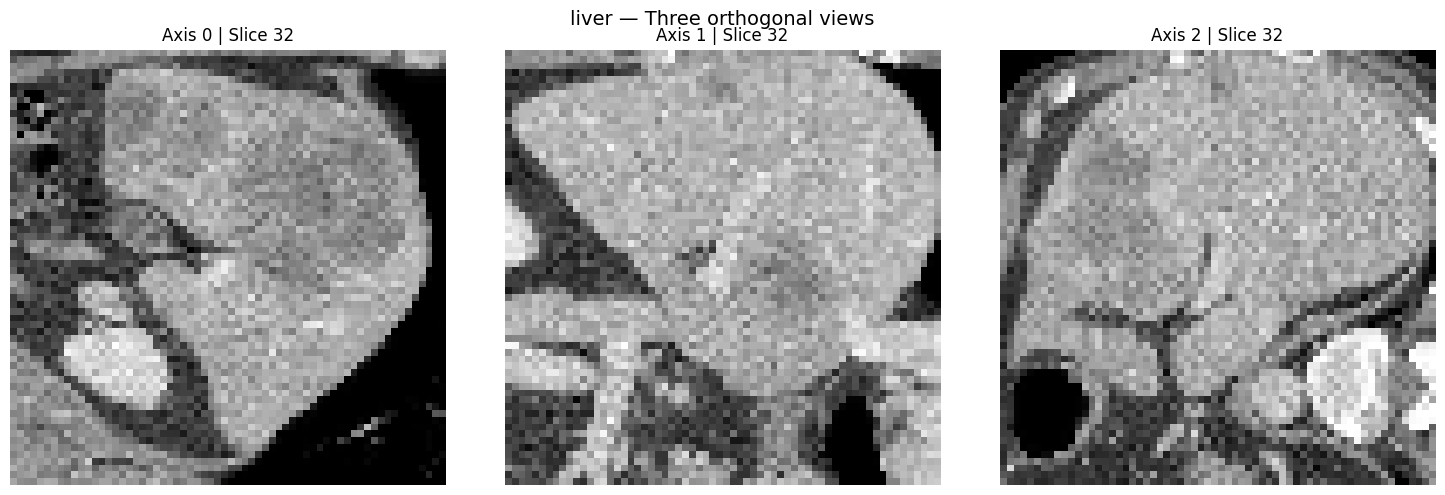

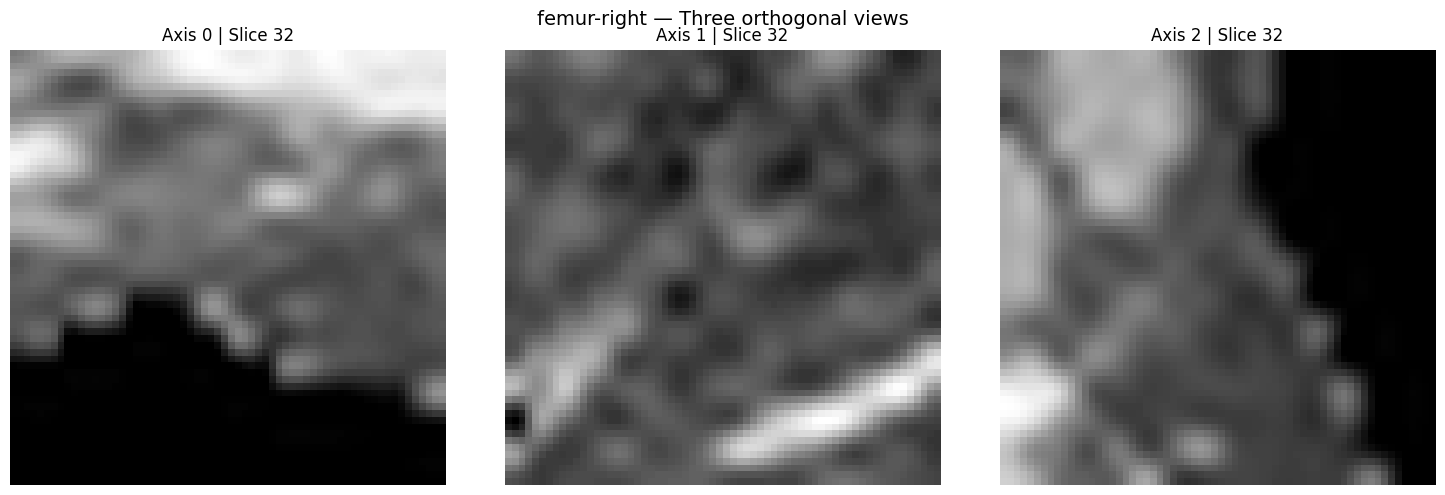

In [5]:
# 3c. Visual inspection of the three orthogonal axes

import matplotlib.pyplot as plt
import numpy as np

# Select one liver and one femur volume
class_names = {int(k): v for k, v in info["label"].items()}

selected_classes = ["liver", "femur-right"]

for class_name in selected_classes:

    class_id = next(
        k for k, v in class_names.items()
        if v == class_name
    )

    idx = np.where(raw["train"].labels.ravel() == class_id)[0][0]

    vol = raw["train"].imgs[idx].astype(np.float32) / 255.0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for axis in range(3):

        slice_idx = vol.shape[axis] // 2
        img = np.take(vol, slice_idx, axis=axis)

        axes[axis].imshow(img, cmap="gray")
        axes[axis].set_title(
            f"Axis {axis} | Slice {slice_idx}"
        )
        axes[axis].axis("off")

    fig.suptitle(
        f"{class_name} — Three orthogonal views",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

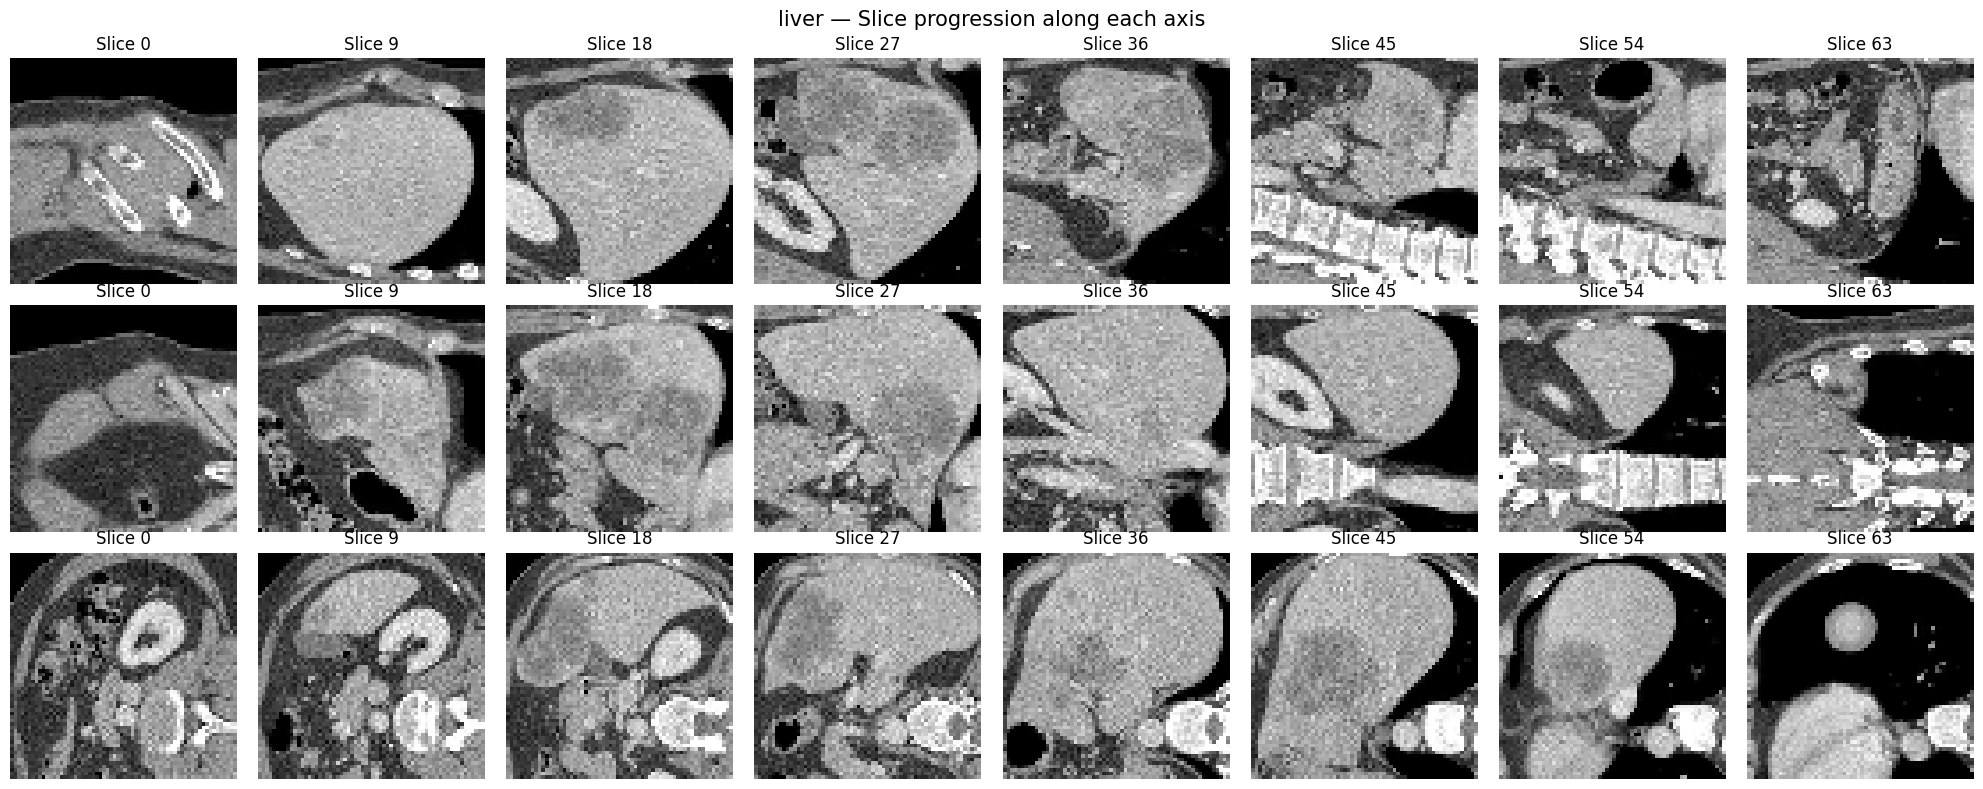

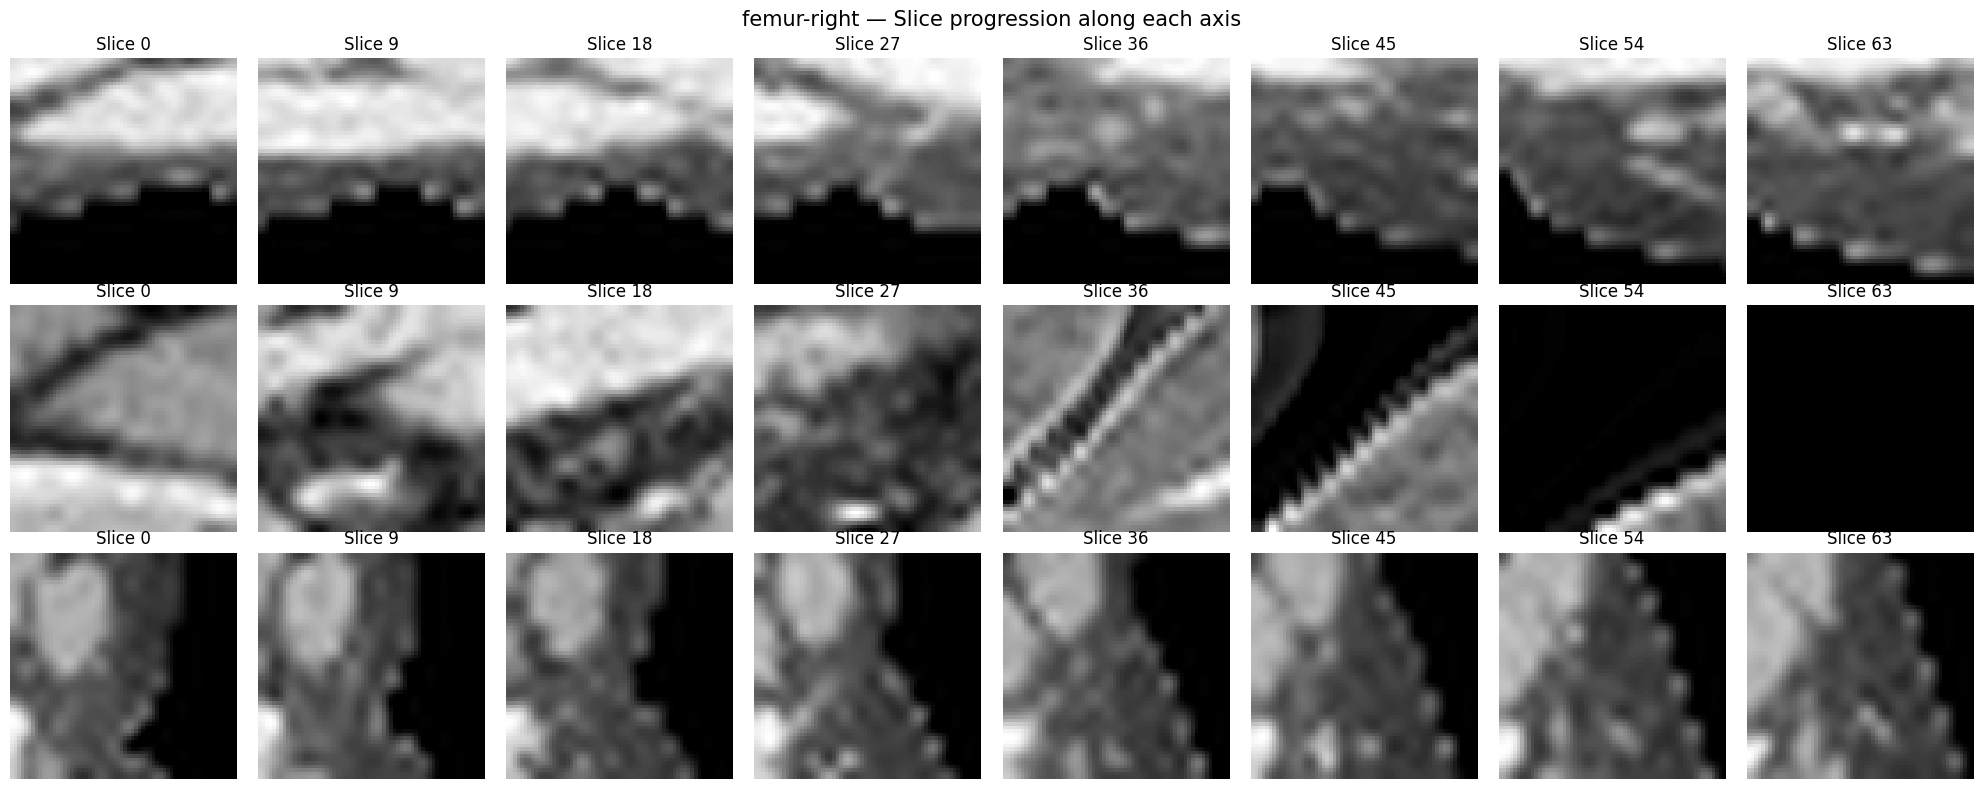

In [6]:
# 3d. Multi-slice inspection along all three axes

import matplotlib.pyplot as plt
import numpy as np

selected_classes = ["liver", "femur-right"]

for class_name in selected_classes:

    class_id = next(
        k for k, v in class_names.items()
        if v == class_name
    )

    idx = np.where(
        raw["train"].labels.ravel() == class_id
    )[0][0]

    vol = raw["train"].imgs[idx].astype(np.float32) / 255.0

    fig, axes = plt.subplots(3, 8, figsize=(20, 8))

    for axis in range(3):

        positions = np.linspace(
            0, vol.shape[axis] - 1, 8, dtype=int
        )

        for j, slice_idx in enumerate(positions):

            img = np.take(vol, slice_idx, axis=axis)

            axes[axis, j].imshow(img, cmap="gray")
            axes[axis, j].set_title(f"Slice {slice_idx}")
            axes[axis, j].axis("off")

        axes[axis, 0].set_ylabel(
            f"Axis {axis}",
            fontsize=12
        )

    fig.suptitle(
        f"{class_name} — Slice progression along each axis",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

In [7]:

# ============================================================
# 3e. Anatomical axis investigation using 2D companion datasets
# ============================================================

import numpy as np
from medmnist import OrganAMNIST, OrganCMNIST, OrganSMNIST

# ------------------------------------------------------------
# 1. Load the official 64x64 companion datasets
# ------------------------------------------------------------

datasets_2d = {
    "Axial": OrganAMNIST(split="train", size=64, download=True),
    "Coronal": OrganCMNIST(split="train", size=64, download=True),
    "Sagittal": OrganSMNIST(split="train", size=64, download=True),
}

# ------------------------------------------------------------
# 2. Prepare the images and labels
# ------------------------------------------------------------

volumes = raw["train"].imgs.astype(np.float32) / 255.0
labels_3d = raw["train"].labels.ravel()

reference_images = {}
reference_labels = {}

for view_name, ds in datasets_2d.items():

    reference_images[view_name] = (
        ds.imgs.astype(np.float32) / 255.0
    )

    reference_labels[view_name] = ds.labels.ravel()

print("========== DATASET SHAPES ==========")
print("3D volumes:", volumes.shape)

for view_name in datasets_2d:
    print(
        f"{view_name:<10}: "
        f"{reference_images[view_name].shape}"
    )

# ------------------------------------------------------------
# 3. Inspect class distributions
# ------------------------------------------------------------

print("\n========== CLASS DISTRIBUTIONS ==========")

for class_id in sorted(class_names):

    class_name = class_names[class_id]

    count_3d = np.sum(labels_3d == class_id)

    print(f"\n{class_name}:")
    print(f"  3D: {count_3d}")

    for view_name in datasets_2d:

        count_2d = np.sum(
            reference_labels[view_name] == class_id
        )

        print(f"  {view_name}: {count_2d}")

# ------------------------------------------------------------
# 4. Generate all eight in-plane orientations
# ------------------------------------------------------------

def get_orientations(image):

    orientations = []

    for k in range(4):

        rotated = np.rot90(image, k=k)

        orientations.append(rotated)
        orientations.append(np.flip(rotated, axis=1))

    return orientations


# ------------------------------------------------------------
# 5. Calculate nearest-reference MAE
# ------------------------------------------------------------

def calculate_nearest_mae(candidate, refs):

    """
    Compare one 64x64 candidate slice with all reference
    images of the same class.

    Returns the smallest MAE across references and
    eight possible in-plane orientations.
    """

    best_error = float("inf")

    candidate_orientations = get_orientations(candidate)

    for ref in refs:

        for oriented_candidate in candidate_orientations:

            mae = np.mean(
                np.abs(oriented_candidate - ref)
            )

            if mae < best_error:
                best_error = mae

    return best_error


# ------------------------------------------------------------
# 6. Compare each 3D axis with each anatomical view
# ------------------------------------------------------------

# Use a deterministic subset to keep execution reasonable.
# Increase this number later if needed.

MAX_VOLUMES_PER_CLASS = 10

results = {}

print("\n========== STARTING COMPARISON ==========")

for axis in range(3):

    print(f"\nProcessing Axis {axis}...")

    for view_name in datasets_2d:

        errors = []

        for class_id in sorted(class_names):

            # Select 3D volumes of the current class
            indices = np.where(
                labels_3d == class_id
            )[0][:MAX_VOLUMES_PER_CLASS]

            # Select 2D references of the same class
            refs = reference_images[view_name][
                reference_labels[view_name] == class_id
            ]

            if len(refs) == 0 or len(indices) == 0:
                continue

            for idx in indices:

                volume = volumes[idx]

                # Test both central slice positions
                for position in [31, 32]:

                    candidate = np.take(
                        volume,
                        position,
                        axis=axis
                    )

                    mae = calculate_nearest_mae(
                        candidate,
                        refs
                    )

                    errors.append(mae)

        results[(axis, view_name)] = (
            np.mean(errors) if errors else np.nan
        )

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n========== AXIS-TO-PLANE COMPARISON ==========")

for axis in range(3):

    print(f"\nAxis {axis}:")

    for view_name in datasets_2d:

        error = results[(axis, view_name)]

        print(
            f"  {view_name:<10}: MAE = {error:.6f}"
        )

# ------------------------------------------------------------
# 8. Display the lowest errors
# ------------------------------------------------------------

print("\n========== LOWEST MAE PER AXIS ==========")

for axis in range(3):

    axis_results = {
        view: results[(axis, view)]
        for view in datasets_2d
    }

    best_view = min(
        axis_results,
        key=axis_results.get
    )

    print(
        f"Axis {axis}: closest to {best_view} "
        f"(MAE = {axis_results[best_view]:.6f})"
    )

print("\nDiagnostic completed.")


100%|██████████| 200M/200M [01:21<00:00, 2.44MB/s]
100%|██████████| 80.3M/80.3M [00:27<00:00, 2.89MB/s]
100%|██████████| 85.9M/85.9M [00:17<00:00, 4.94MB/s]


========== DATASET SHAPES ==========
3D volumes: (971, 64, 64, 64)
Axial     : (34561, 64, 64)
Coronal   : (12975, 64, 64)
Sagittal  : (13932, 64, 64)

========== CLASS DISTRIBUTIONS ==========

liver:
  3D: 115
  Axial: 1956
  Coronal: 1148
  Sagittal: 1148

kidney-right:
  3D: 115
  Axial: 1390
  Coronal: 619
  Sagittal: 630

kidney-left:
  3D: 115
  Axial: 1357
  Coronal: 595
  Sagittal: 614

femur-right:
  3D: 91
  Axial: 1474
  Coronal: 600
  Sagittal: 721

femur-left:
  3D: 93
  Axial: 3963
  Coronal: 1088
  Sagittal: 1132

bladder:
  3D: 94
  Axial: 3817
  Coronal: 1170
  Sagittal: 1119

heart:
  3D: 40
  Axial: 6164
  Coronal: 2986
  Sagittal: 3464

lung-right:
  3D: 39
  Axial: 3919
  Coronal: 1002
  Sagittal: 741

lung-left:
  3D: 39
  Axial: 3929
  Coronal: 1022
  Sagittal: 803

spleen:
  3D: 115
  Axial: 3031
  Coronal: 1173
  Sagittal: 2004

pancreas:
  3D: 115
  Axial: 3561
  Coronal: 1572
  Sagittal: 1556

========== STARTING COMPARISON ==========

Processing Axis 0...



In [8]:

# ============================================================
# CELL 3f — OFFICIAL MEDMNIST LOADER VERIFICATION
# ============================================================

print("=" * 75)
print("ORGANMNIST3D: OFFICIAL LOADER AND SPATIAL DIMENSION VERIFICATION")
print("=" * 75)

# 1. Inspect the stored dataset
print("\n[1] STORED DATASET INFORMATION")

for split in ("train", "val", "test"):
    print(
        f"{split:5s} | "
        f"images: {raw[split].imgs.shape} | "
        f"labels: {raw[split].labels.shape} | "
        f"dtype: {raw[split].imgs.dtype}"
    )

# 2. Retrieve one sample using the official MedMNIST loader
print("\n[2] OFFICIAL MEDMNIST3D.__getitem__ OUTPUT")

sample_img, sample_label = raw["train"][0]

print("Stored volume shape:", raw["train"].imgs[0].shape)
print("Loaded image shape:", sample_img.shape)
print("Loaded image dtype:", sample_img.dtype)
print("Label:", sample_label)

# 3. Verify spatial dimensions
print("\n[3] SPATIAL DIMENSION PRESERVATION")

stored_shape = raw["train"].imgs[0].shape
loaded_spatial_shape = sample_img.shape[1:]

print("Stored spatial dimensions:", stored_shape)
print("Loaded spatial dimensions:", loaded_spatial_shape)

assert stored_shape == loaded_spatial_shape, (
    "Spatial dimensions have changed!"
)

print("PASS: The official loader preserves all three spatial dimensions.")

# 4. Verify intensity scaling
print("\n[4] INTENSITY SCALING")

expected_img = raw["train"].imgs[0] / 255.0

scaling_matches = np.allclose(
    sample_img[0],
    expected_img,
    atol=1e-6
)

print("Stored volume / 255 matches loaded volume:", scaling_matches)

assert scaling_matches, (
    "Unexpected intensity transformation in the official loader."
)

print("PASS: Intensity scaling is consistent with division by 255.")

# 5. Check configured transformations
print("\n[5] TRANSFORMATION CONFIGURATION")

print("Official loader transform:", raw["train"].transform)
print("RGB conversion:", raw["train"].as_rgb)

# 6. Final interpretation
print("\n[6] CONCLUSION")

print("- The official loader retrieves the stored 3D volume.")
print("- It divides intensities by 255.")
print("- It adds a channel dimension.")
print("- No explicit spatial transpose or flip is performed")
print("  in the official MedMNIST3D.__getitem__ implementation.")

print("\nIMPORTANT:")
print("This verifies the loading behavior only.")
print("It does NOT establish the anatomical correspondence")
print("between array axes 0, 1, 2 and axial, coronal, sagittal planes.")

print("=" * 75)


ORGANMNIST3D: OFFICIAL LOADER AND SPATIAL DIMENSION VERIFICATION

[1] STORED DATASET INFORMATION
train | images: (971, 64, 64, 64) | labels: (971, 1) | dtype: uint8
val   | images: (161, 64, 64, 64) | labels: (161, 1) | dtype: uint8
test  | images: (610, 64, 64, 64) | labels: (610, 1) | dtype: uint8

[2] OFFICIAL MEDMNIST3D.__getitem__ OUTPUT
Stored volume shape: (64, 64, 64)
Loaded image shape: (1, 64, 64, 64)
Loaded image dtype: float64
Label: [3]

[3] SPATIAL DIMENSION PRESERVATION
Stored spatial dimensions: (64, 64, 64)
Loaded spatial dimensions: (64, 64, 64)
PASS: The official loader preserves all three spatial dimensions.

[4] INTENSITY SCALING
Stored volume / 255 matches loaded volume: True
PASS: Intensity scaling is consistent with division by 255.

[5] TRANSFORMATION CONFIGURATION
Official loader transform: None
RGB conversion: False

[6] CONCLUSION
- The official loader retrieves the stored 3D volume.
- It divides intensities by 255.
- It adds a channel dimension.
- No explic

## 4. 3D volume preprocessing

The dataset only converts to float32 in [0, 1] and adds the channel axis. Normalization statistics come from the **train split only**, and the same constants are used for every split and every view **[C]**.

In [9]:
class VolumeDataset(Dataset):
    """(volume [1,D,H,W] float32 in [0,1], label int64, dataset_index int64)."""
    def __init__(self, imgs, labels):
        assert imgs.ndim == 4
        self.imgs, self.labels = imgs, labels.reshape(-1).astype(np.int64)
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        vol = torch.from_numpy(self.imgs[i]).float().div_(255.0).unsqueeze(0)
        return vol, torch.tensor(self.labels[i]), torch.tensor(i)


def train_intensity_stats(imgs, chunk=64):
    n, s, ss = 0, 0.0, 0.0
    for i in range(0, len(imgs), chunk):
        x = imgs[i:i + chunk].astype(np.float64) / 255.0
        n += x.size; s += x.sum(); ss += (x ** 2).sum()
    mean = s / n
    return float(mean), float((ss / n - mean ** 2) ** 0.5)


class SliceNormalizer:
    """Per-channel affine normalization applied to resized slices, identical for all views.
    (Affine ops commute with bilinear resizing, so this equals normalizing the volume first.)"""
    def __init__(self, mode, train_stats, channels, device):
        if mode == "zscore_train":
            mean, std = [train_stats[0]] * channels, [train_stats[1]] * channels
        elif mode == "imagenet":
            assert channels == 3, "imagenet mode needs 3 channels"
            mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
        elif mode == "none01":
            mean, std = [0.0] * channels, [1.0] * channels
        else:
            raise ValueError(mode)
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
    def __call__(self, x): return (x - self.mean) / self.std


datasets = {s: VolumeDataset(ds.imgs, ds.labels) for s, ds in raw.items()}
train_stats = train_intensity_stats(raw["train"].imgs)          # fitted on TRAIN only
print("train intensity mean/std (in [0,1]):", train_stats)

train intensity mean/std (in [0,1]): (0.5059536319550181, 0.2787706929971837)


## 5. Axial, coronal and sagittal slice extraction

Each view is a permutation that moves the slicing axis to position 1 (no copy, no reinterpretation), so slice order and the link to the source volume are preserved.
The array-axis mapping (axis 0 = axial) is an assumption **[C]** - check the figure below.

In [10]:
VIEWS = ("axial", "coronal", "sagittal")
# x: [B,1,D,H,W]  ->  [B,S,1,h,w]
VIEW_PERMUTATIONS = {
    "axial":    (0, 2, 1, 3, 4),   # slice s = x[:, :, s]        (plane H x W)
    "coronal":  (0, 3, 1, 2, 4),   # slice s = x[:, :, :, s]     (plane D x W)
    "sagittal": (0, 4, 1, 2, 3),   # slice s = x[:, :, :, :, s]  (plane D x H)
}


def extract_view(x, view):
    assert x.ndim == 5 and x.shape[1] == 1, tuple(x.shape)
    return x.permute(*VIEW_PERMUTATIONS[view])


def select_slice_indices(depth, num_slices):
    if num_slices > depth:
        raise ValueError(f"num_slices={num_slices} > {depth}")
    if num_slices == depth:
        return torch.arange(depth)
    return torch.linspace(0, depth - 1, num_slices).round().long()   # deterministic, sorted


def resize_slices(slices, size, mode):
    """[N,1,h,w] -> [N,1,size,size]. Upsampling 64 -> 224 (224 = 14 patches of 16)."""
    return F.interpolate(slices, size=(size, size), mode=mode, align_corners=False)

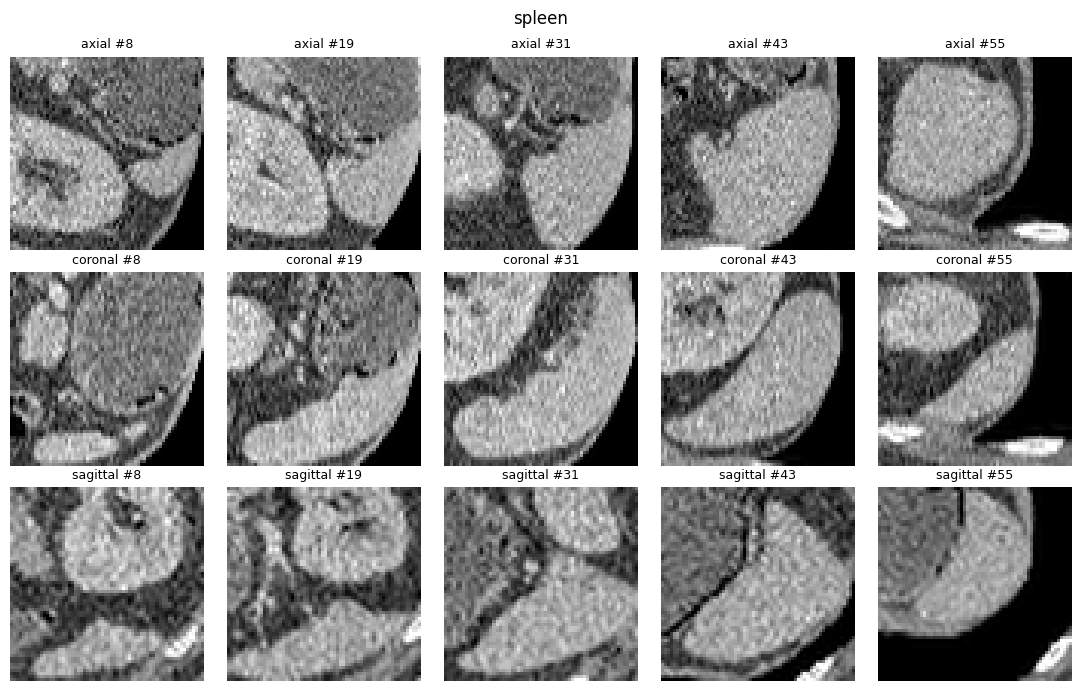

In [11]:
# Orientation check: the "axial" row should look like normal axial CT crops.
# If not, only the names in VIEW_PERMUTATIONS need to change.
import matplotlib.pyplot as plt
x, y, _ = datasets["val"][0]
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for r, view in enumerate(VIEWS):
    sl = extract_view(x.unsqueeze(0), view)[0, :, 0]
    for c, s in enumerate(np.linspace(8, 55, 5).astype(int)):
        axes[r, c].imshow(sl[s], cmap="gray"); axes[r, c].axis("off"); axes[r, c].set_title(f"{view} #{s}", fontsize=9)
plt.suptitle(info["label"][str(int(y))]); plt.tight_layout(); plt.show()

In [12]:

# CELL 3g — FEMUR ANATOMICAL AXIS DIAGNOSTIC

imgs = raw["train"].imgs.astype(np.float32) / 255.0
y = raw["train"].labels.ravel()

G = np.stack([
    [np.abs(np.diff(v, axis=a)).mean() for a in range(3)]
    for v in imgs
])

names = {int(k): v for k, v in info["label"].items()}

print("FEMUR AXIS COMPARISON")
print("-" * 75)

for class_id in (3, 4):
    mask = y == class_id
    gradients = G[mask]

    mean_grad = gradients.mean(axis=0)
    winners = np.bincount(
        gradients.argmin(axis=1),
        minlength=3
    )

    percentages = winners / len(gradients) * 100

    print(f"\n{names[class_id]} | N={len(gradients)}")
    print("Mean gradients:", mean_grad)
    print("Smallest gradient (%):", percentages)


FEMUR AXIS COMPARISON
---------------------------------------------------------------------------

femur-right | N=91
Mean gradients: [0.02589969 0.02749345 0.02291691]
Smallest gradient (%): [13.18681319 15.38461538 71.42857143]

femur-left | N=93
Mean gradients: [0.02730211 0.02790628 0.02405768]
Smallest gradient (%): [10.75268817 20.43010753 68.8172043 ]


ORGANMNIST3D — COMPARISON WITH OFFICIAL 2D ANATOMICAL VIEWS


100%|██████████| 200M/200M [00:59<00:00, 3.37MB/s]


axial      | organamnist     | images: (34561, 64, 64) | labels: (34561, 1)


100%|██████████| 80.3M/80.3M [00:31<00:00, 2.52MB/s]


coronal    | organcmnist     | images: (12975, 64, 64) | labels: (12975, 1)


100%|██████████| 85.9M/85.9M [01:24<00:00, 1.02MB/s]


sagittal   | organsmnist     | images: (13932, 64, 64) | labels: (13932, 1)

CURRENT 3D VIEW MAPPING
--------------------------------------------------------------------------------
axial      | permutation: (0, 2, 1, 3, 4) | original volume axis: 0
coronal    | permutation: (0, 3, 1, 2, 4) | original volume axis: 1
sagittal   | permutation: (0, 4, 1, 2, 3) | original volume axis: 2


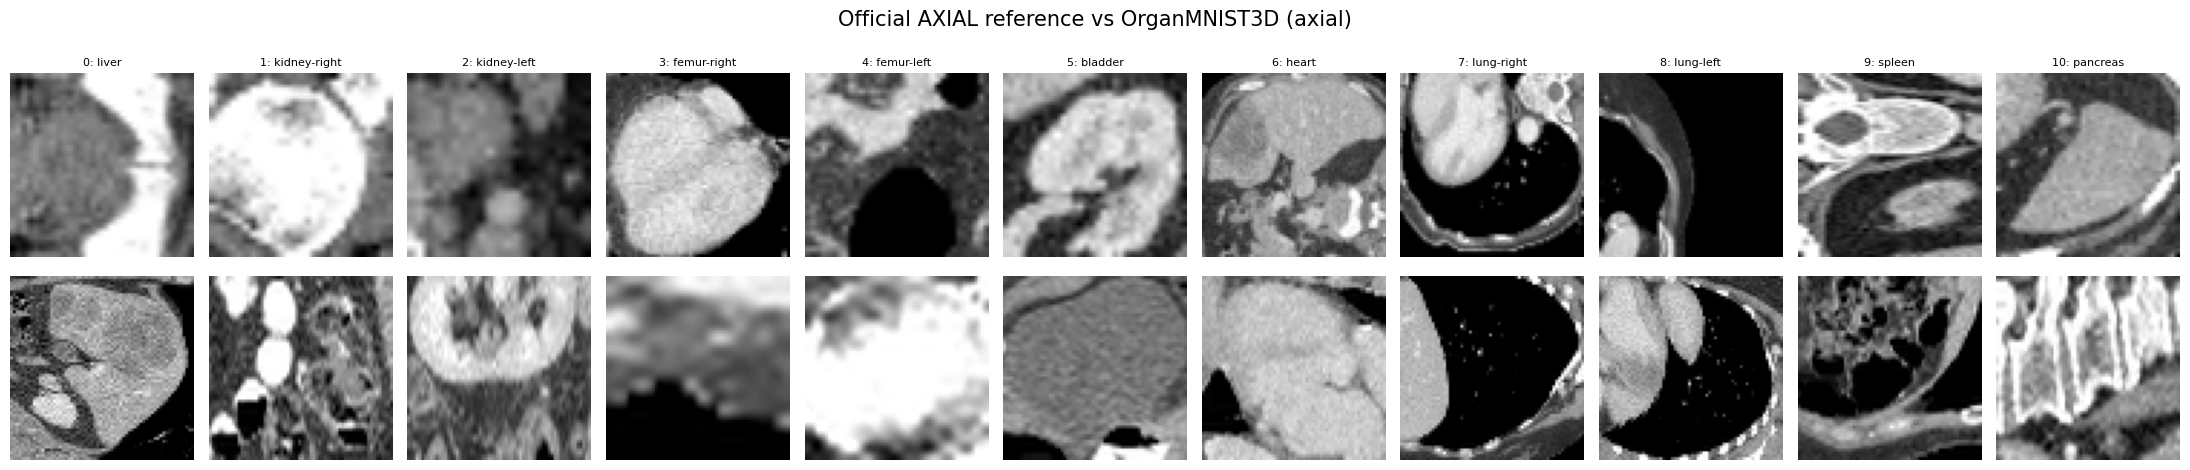

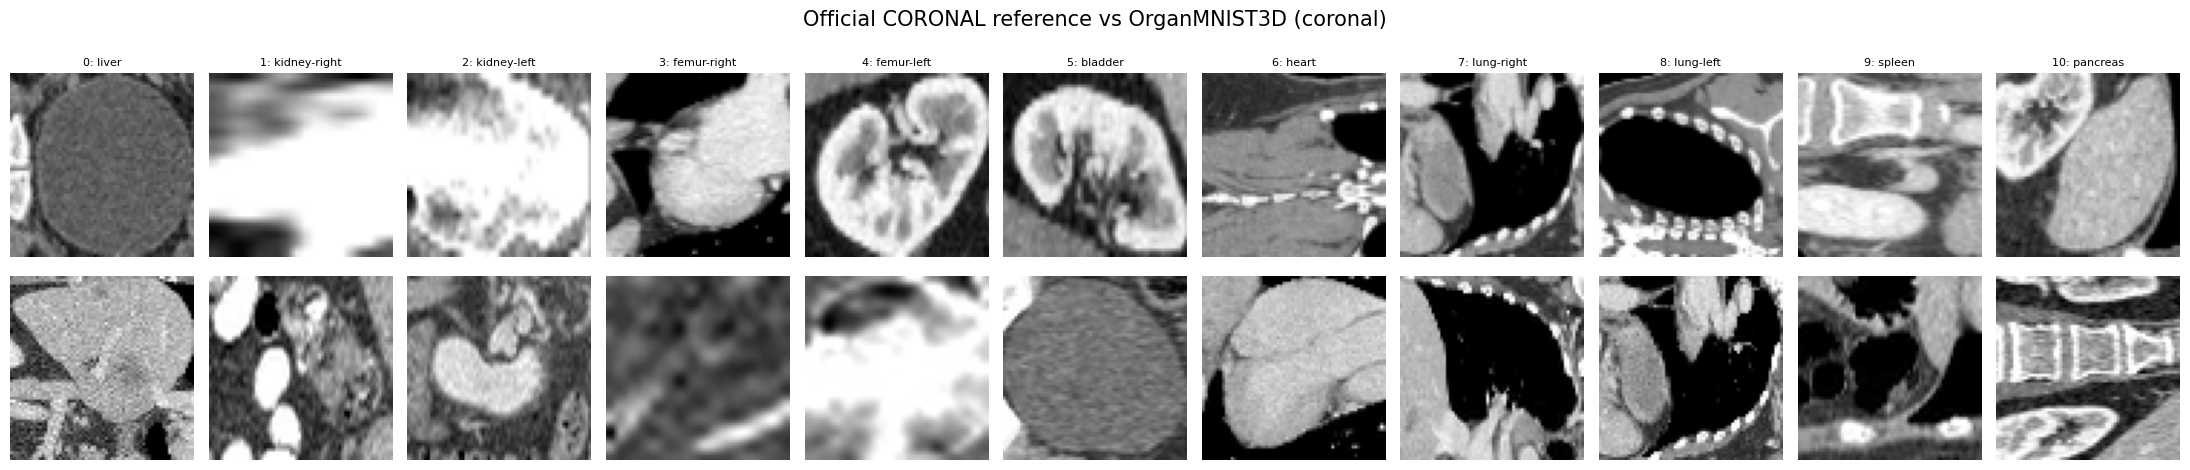

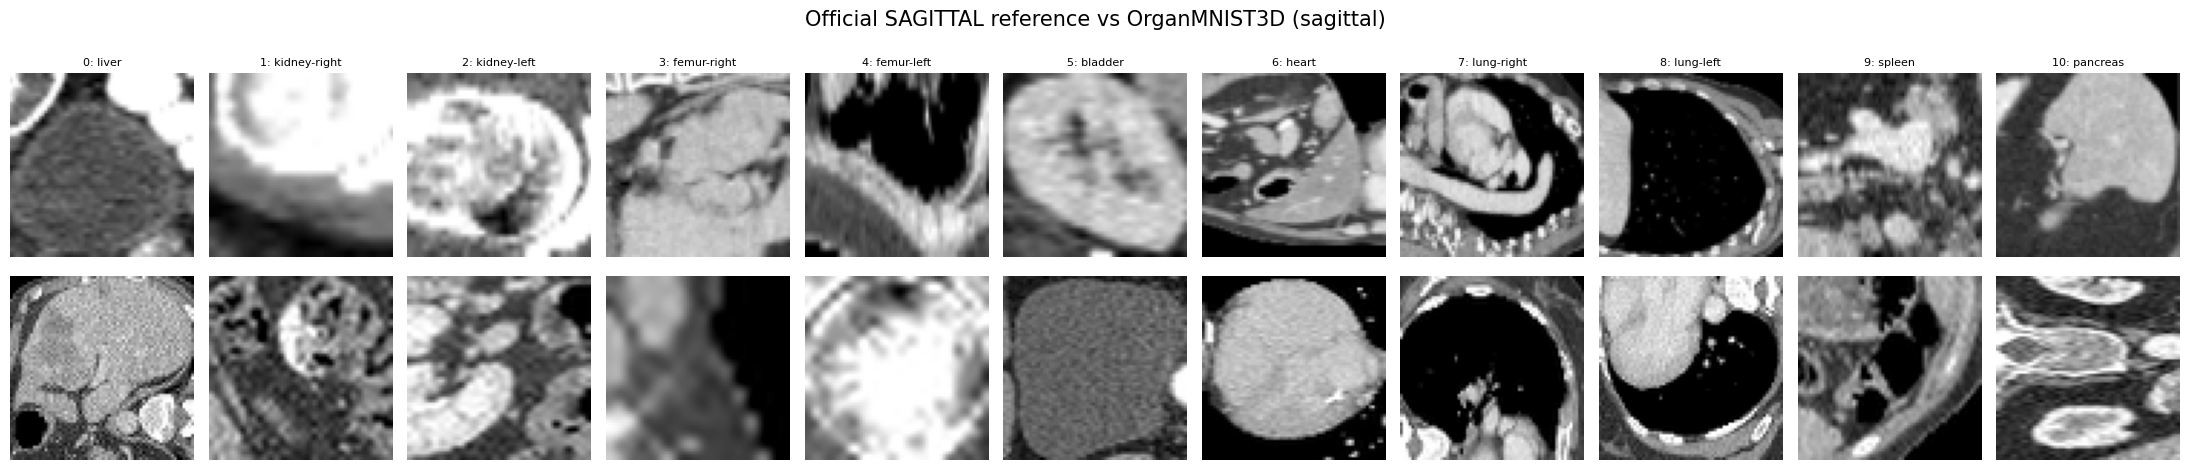


COMPARISON COMPLETED
No permutations, normalization, or extracted features were modified.


In [13]:

# CELL 5c — ANATOMICAL ORIENTATION VERIFICATION
# Compare OrganMNIST3D central slices with official 2D OrganMNIST datasets.
# Diagnostic only: does not modify the existing pipeline or saved features.

import medmnist
import numpy as np
import matplotlib.pyplot as plt

print("=" * 80)
print("ORGANMNIST3D — COMPARISON WITH OFFICIAL 2D ANATOMICAL VIEWS")
print("=" * 80)

# 1. Load the three official 2D datasets
reference_datasets = {
    "axial": "organamnist",
    "coronal": "organcmnist",
    "sagittal": "organsmnist"
}

raw_2d = {}

for view, dataset_flag in reference_datasets.items():

    dataset_info = medmnist.INFO[dataset_flag]
    Dataset2D = getattr(medmnist, dataset_info["python_class"])

    raw_2d[view] = Dataset2D(
        split="train",
        download=True,
        root=cfg.data_root,
        size=cfg.medmnist_size
    )

    print(
        f"{view:10s} | {dataset_flag:15s} | "
        f"images: {raw_2d[view].imgs.shape} | "
        f"labels: {raw_2d[view].labels.shape}"
    )

# 2. Verify the actual slicing axis in your existing implementation
print("\nCURRENT 3D VIEW MAPPING")
print("-" * 80)

for view in VIEWS:
    permutation = VIEW_PERMUTATIONS[view]
    slicing_axis = permutation[1] - 2

    print(
        f"{view:10s} | permutation: {permutation} | "
        f"original volume axis: {slicing_axis}"
    )

# 3. Compare representative samples class by class
labels_3d = raw["train"].labels.ravel()

for view in VIEWS:

    reference = raw_2d[view]
    labels_2d = reference.labels.ravel()

    fig, axes = plt.subplots(
        2, 11,
        figsize=(22, 5)
    )

    fig.suptitle(
        f"Official {view.upper()} reference vs OrganMNIST3D ({view})",
        fontsize=15
    )

    for class_id in range(11):

        idx_2d = np.where(labels_2d == class_id)[0]
        idx_3d = np.where(labels_3d == class_id)[0]

        if len(idx_2d) == 0 or len(idx_3d) == 0:
            axes[0, class_id].axis("off")
            axes[1, class_id].axis("off")
            continue

        # Select one representative sample from each dataset
        sample_2d = np.squeeze(reference.imgs[idx_2d[0]])

        sample_3d, label, _ = datasets["train"][int(idx_3d[0])]

        # Extract the central slice using the EXISTING function
        volume = sample_3d.unsqueeze(0)
        extracted = extract_view(volume, view)

        central_slice = extracted[0, 32, 0].numpy()

        # Display official 2D reference
        axes[0, class_id].imshow(sample_2d, cmap="gray")
        axes[0, class_id].axis("off")

        # Display central slice from 3D volume
        axes[1, class_id].imshow(central_slice, cmap="gray")
        axes[1, class_id].axis("off")

        class_name = info["label"][str(class_id)]

        axes[0, class_id].set_title(
            f"{class_id}: {class_name}",
            fontsize=8
        )

    axes[0, 0].set_ylabel("Official 2D", fontsize=10)
    axes[1, 0].set_ylabel("3D central", fontsize=10)

    plt.tight_layout()
    plt.show()

print("\nCOMPARISON COMPLETED")
print("No permutations, normalization, or extracted features were modified.")


3D ORGAN LABELS:
 0 -> liver
 1 -> kidney-right
 2 -> kidney-left
 3 -> femur-right
 4 -> femur-left
 5 -> bladder
 6 -> heart
 7 -> lung-right
 8 -> lung-left
 9 -> spleen
10 -> pancreas

AXIAL — ORGAN NAME MATCHING
liver           | 2D class= 6 | 3D class= 0


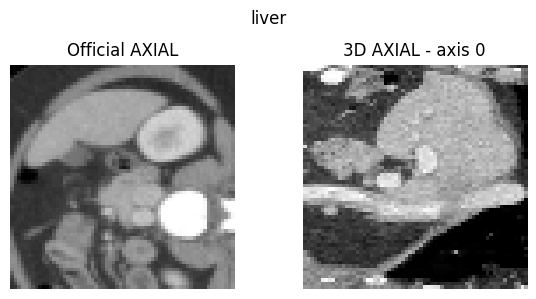

kidney-right    | 2D class= 5 | 3D class= 1


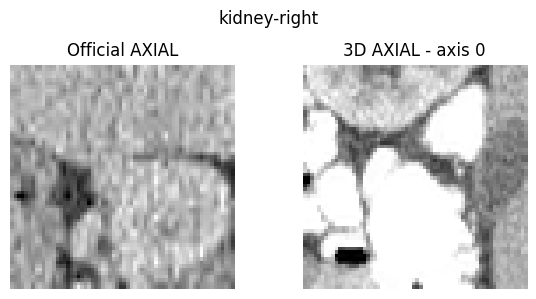

kidney-left     | 2D class= 4 | 3D class= 2


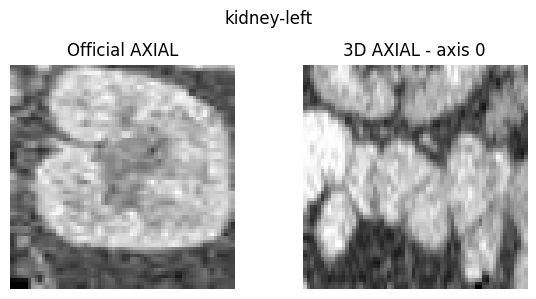

femur-right     | 2D class= 2 | 3D class= 3


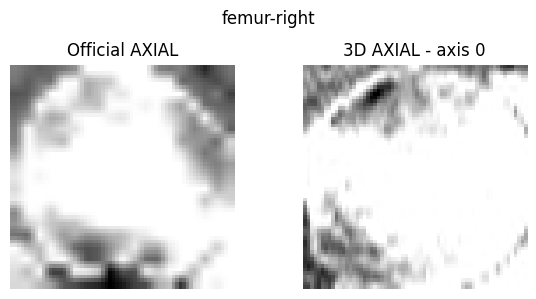

femur-left      | 2D class= 1 | 3D class= 4


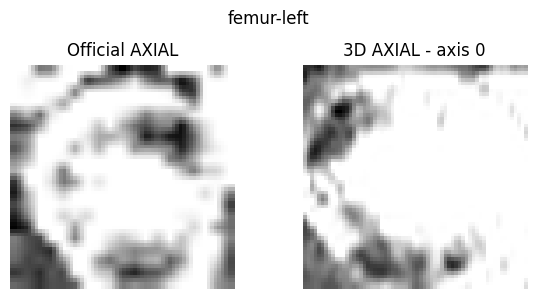

bladder         | 2D class= 0 | 3D class= 5


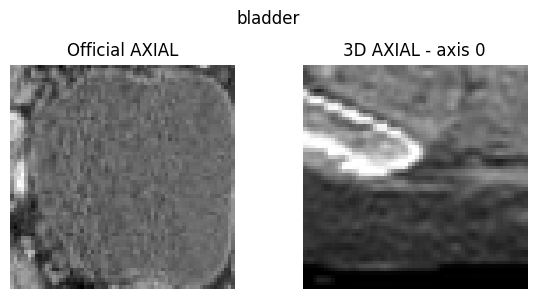

heart           | 2D class= 3 | 3D class= 6


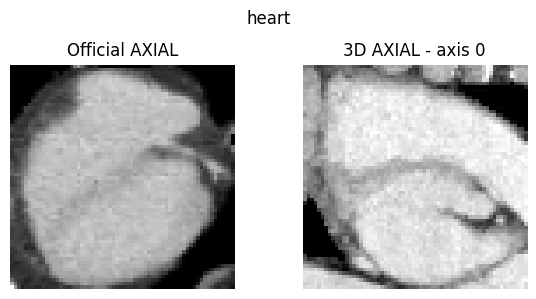

lung-right      | 2D class= 8 | 3D class= 7


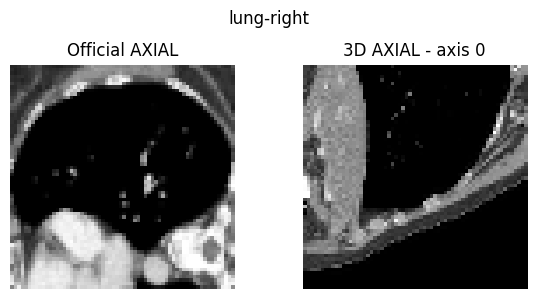

lung-left       | 2D class= 7 | 3D class= 8


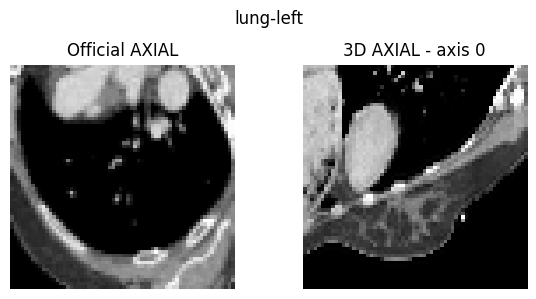

spleen          | 2D class=10 | 3D class= 9


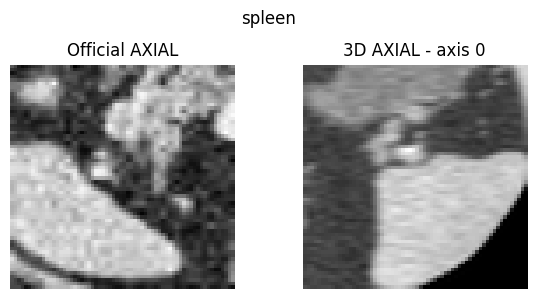

pancreas        | 2D class= 9 | 3D class=10


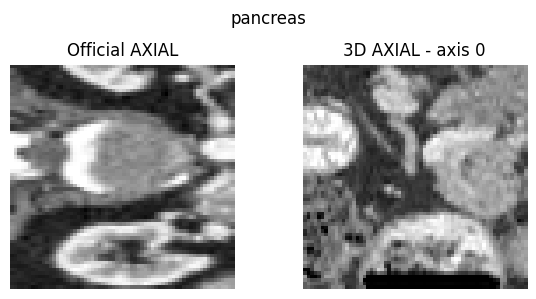


CORONAL — ORGAN NAME MATCHING
liver           | 2D class= 6 | 3D class= 0


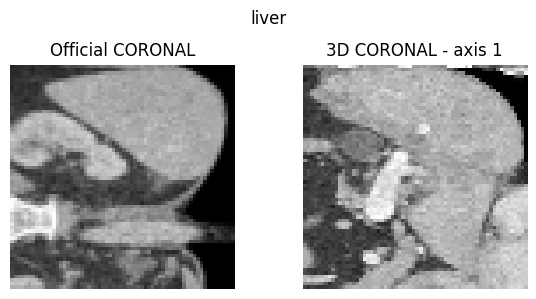

kidney-right    | 2D class= 5 | 3D class= 1


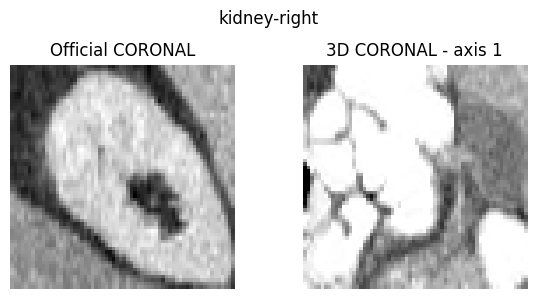

kidney-left     | 2D class= 4 | 3D class= 2


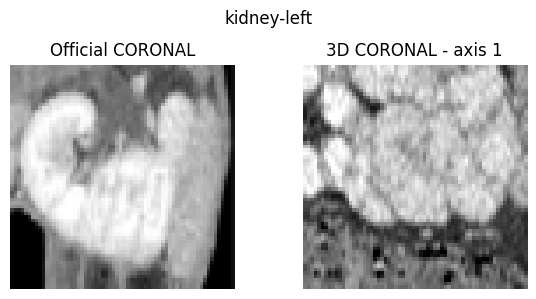

femur-right     | 2D class= 2 | 3D class= 3


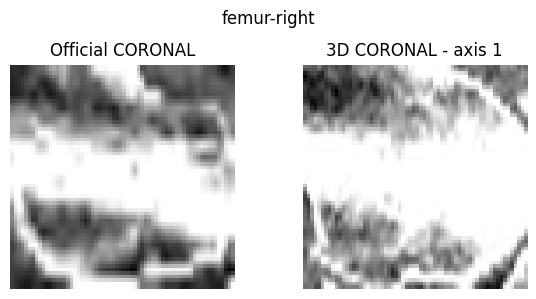

femur-left      | 2D class= 1 | 3D class= 4


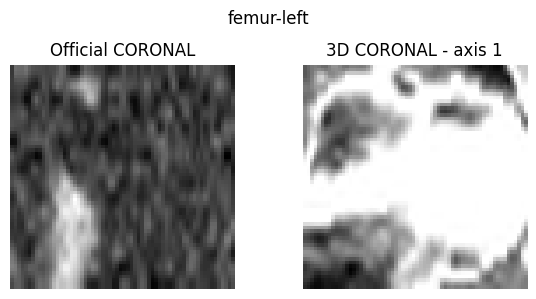

bladder         | 2D class= 0 | 3D class= 5


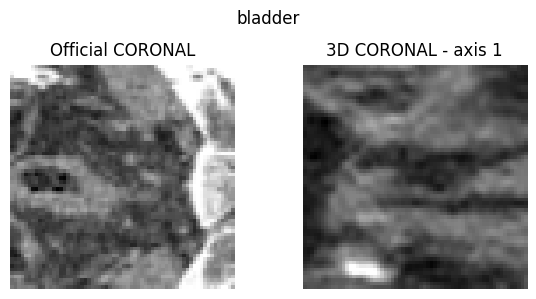

heart           | 2D class= 3 | 3D class= 6


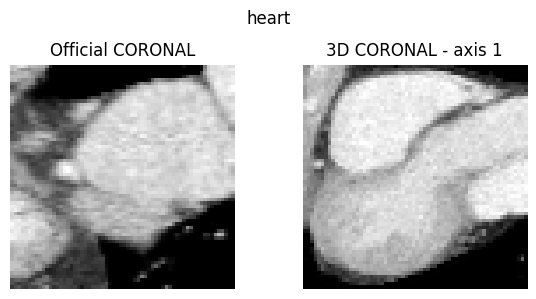

lung-right      | 2D class= 8 | 3D class= 7


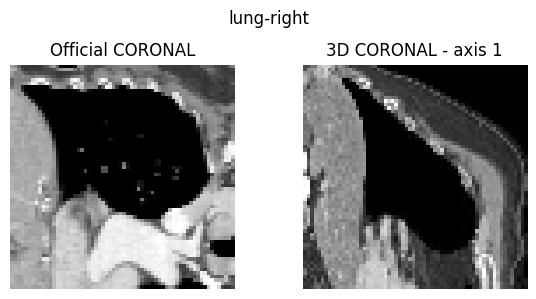

lung-left       | 2D class= 7 | 3D class= 8


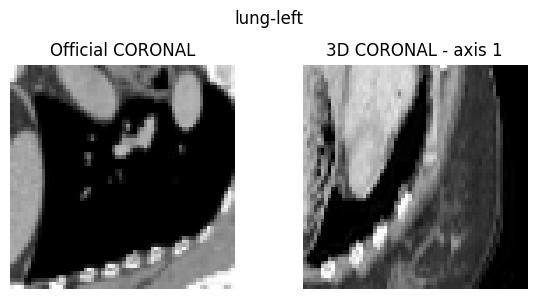

spleen          | 2D class=10 | 3D class= 9


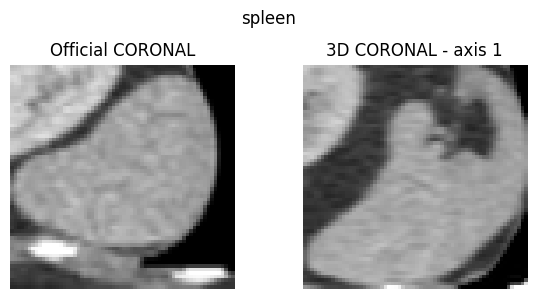

pancreas        | 2D class= 9 | 3D class=10


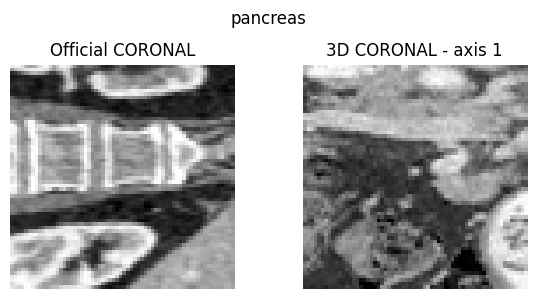


SAGITTAL — ORGAN NAME MATCHING
liver           | 2D class= 6 | 3D class= 0


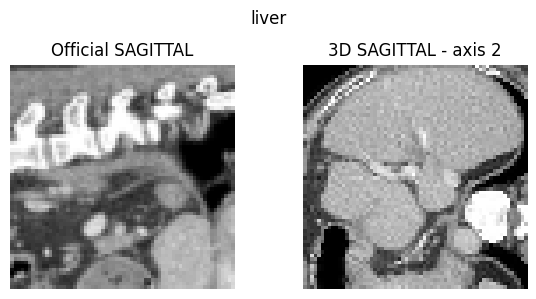

kidney-right    | 2D class= 5 | 3D class= 1


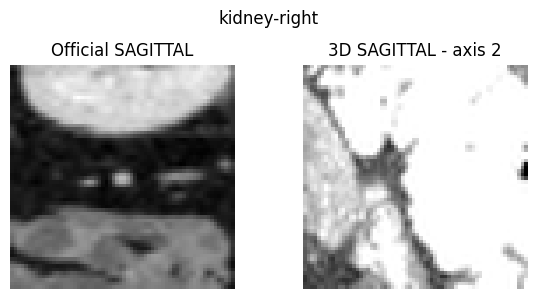

kidney-left     | 2D class= 4 | 3D class= 2


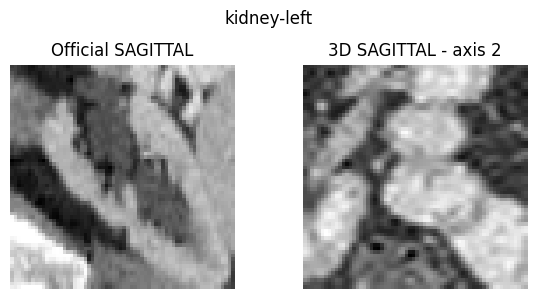

femur-right     | 2D class= 2 | 3D class= 3


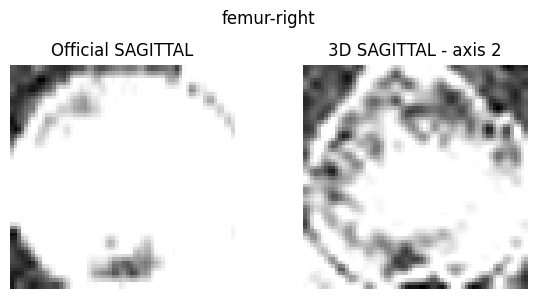

femur-left      | 2D class= 1 | 3D class= 4


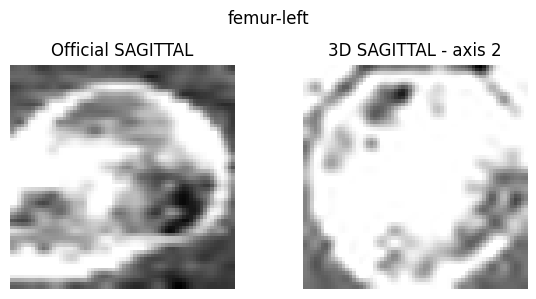

bladder         | 2D class= 0 | 3D class= 5


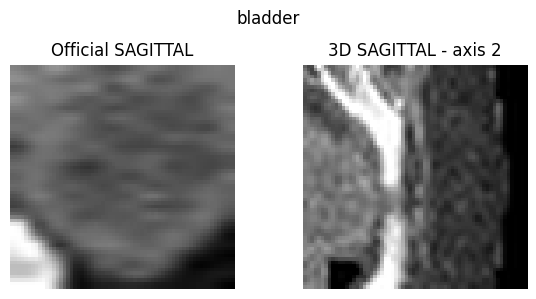

heart           | 2D class= 3 | 3D class= 6


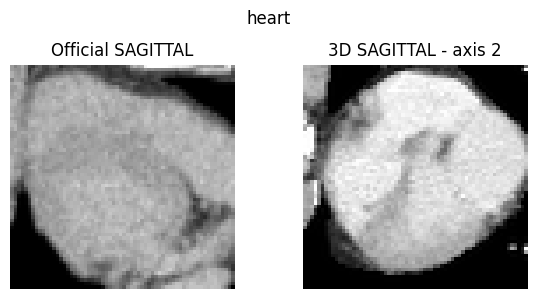

lung-right      | 2D class= 8 | 3D class= 7


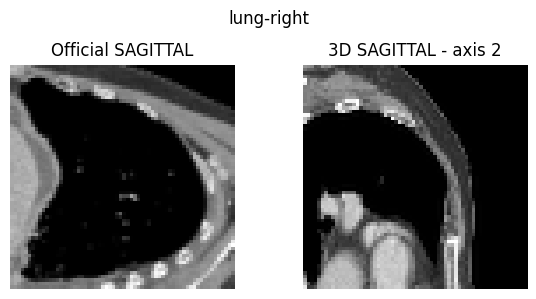

lung-left       | 2D class= 7 | 3D class= 8


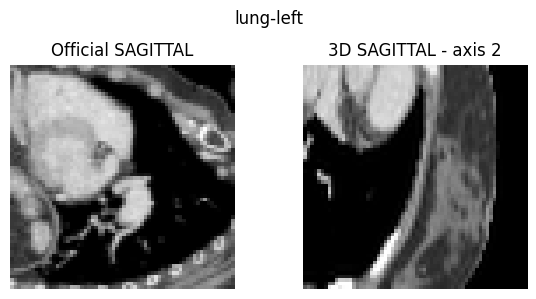

spleen          | 2D class=10 | 3D class= 9


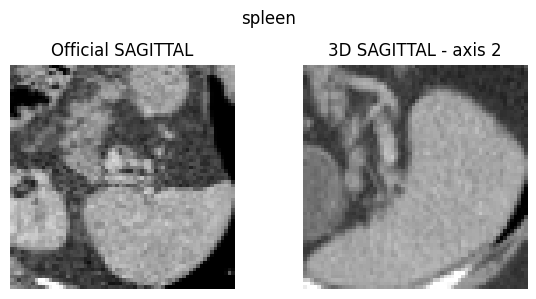

pancreas        | 2D class= 9 | 3D class=10


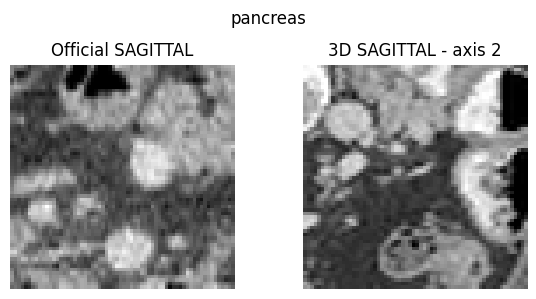


Corrected comparison completed.
No existing preprocessing or features were modified.


In [14]:

# CELL 5d — CORRECTED ANATOMICAL ORIENTATION COMPARISON
# Match 2D and 3D datasets by ORGAN NAME, not by class ID.

import numpy as np
import matplotlib.pyplot as plt
import medmnist

def normalize_organ_name(name):
    return str(name).strip().lower().replace("_", "-").replace(" ", "-")

# 1. Get the label dictionaries
labels_3d = {
    normalize_organ_name(v): int(k)
    for k, v in info["label"].items()
}

print("3D ORGAN LABELS:")
for name, class_id in labels_3d.items():
    print(f"{class_id:2d} -> {name}")

# 2. Compare each anatomical view
for view, dataset_flag in {
    "axial": "organamnist",
    "coronal": "organcmnist",
    "sagittal": "organsmnist"
}.items():

    reference = raw_2d[view]

    info_2d = medmnist.INFO[dataset_flag]

    labels_2d = {
        normalize_organ_name(v): int(k)
        for k, v in info_2d["label"].items()
    }

    print("\n" + "=" * 75)
    print(f"{view.upper()} — ORGAN NAME MATCHING")
    print("=" * 75)

    # Match class IDs using organ names
    for organ_name, class_id_3d in labels_3d.items():

        if organ_name not in labels_2d:
            print(f"WARNING: {organ_name} not found in {dataset_flag}")
            continue

        class_id_2d = labels_2d[organ_name]

        idx_2d = np.where(
            reference.labels.ravel() == class_id_2d
        )[0]

        idx_3d = np.where(
            raw["train"].labels.ravel() == class_id_3d
        )[0]

        if len(idx_2d) == 0 or len(idx_3d) == 0:
            continue

        # Select deterministic representative samples
        sample_2d = np.squeeze(
            reference.imgs[idx_2d[len(idx_2d) // 2]]
        )

        sample_idx_3d = int(idx_3d[len(idx_3d) // 2])

        sample_3d, _, _ = datasets["train"][sample_idx_3d]

        # Use existing extraction function and current mapping
        extracted = extract_view(
            sample_3d.unsqueeze(0),
            view
        )

        central_slice = extracted[0, 32, 0].numpy()

        print(
            f"{organ_name:15s} | "
            f"2D class={class_id_2d:2d} | "
            f"3D class={class_id_3d:2d}"
        )

        # Display comparison
        fig, axes = plt.subplots(1, 2, figsize=(6, 3))

        axes[0].imshow(sample_2d, cmap="gray")
        axes[0].set_title(f"Official {view.upper()}")
        axes[0].axis("off")

        axes[1].imshow(central_slice, cmap="gray")
        axes[1].set_title(f"3D {view.upper()} - axis {VIEW_PERMUTATIONS[view][1]-2}")
        axes[1].axis("off")

        fig.suptitle(organ_name, fontsize=12)
        plt.tight_layout()
        plt.show()

print("\nCorrected comparison completed.")
print("No existing preprocessing or features were modified.")


## 6. Official MedDINOv3 loading

- Official kwargs (README / model card): `vit_base(drop_path_rate=0.0, layerscale_init=1.0e-05, n_storage_tokens=4, qkv_bias=False, mask_k_bias=True)` **[B]**.
- The repo's `models/__init__.py` does `from dinov3.layers...`, so the folder `nnUNetTrainer/dinov3/` must be on `sys.path` (fix for the `No module named 'dinov3'` error). Do **not** `pip install dinov3`.
- Handles both checkpoint layouts (README: `chkpt["teacher"]` with `backbone.` prefix; model card: plain state dict) and **raises** if core weights are missing (`strict=False` could silently leave random layers).
- The HF file is `model.pth`, although the model card mentions `MedDINOv3-B-CT3M.pth`.

In [15]:
INNER_PARENT = f"{cfg.repo_dir}/nnUNet/nnunetv2/training/nnUNetTrainer/dinov3"
print("INNER_PARENT contents:", os.listdir(INNER_PARENT))                 # expect 'dinov3'
print("inner dinov3 contents:", os.listdir(f"{INNER_PARENT}/dinov3"))     # expect layers, models, ...
if INNER_PARENT not in sys.path:
    sys.path.insert(0, INNER_PARENT)


def import_vit_base():
    # Same file as the official snippet, imported as `dinov3.models...` so the repo's own
    # `from dinov3.layers...` imports resolve.
    try:
        from dinov3.models.vision_transformer import vit_base
    except ModuleNotFoundError as e:
        raise RuntimeError(f"Import failed on missing module: {e.name}") from e
    return vit_base


def get_checkpoint(cfg):
    if cfg.ckpt_path and os.path.exists(cfg.ckpt_path):
        return cfg.ckpt_path
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id=cfg.hf_repo_id, filename=cfg.hf_filename,
                           local_dir="/kaggle/working/meddinov3_ckpt")


def load_meddinov3(cfg, device):
    vit_base = import_vit_base()
    model = vit_base(drop_path_rate=0.0, layerscale_init=1.0e-05, n_storage_tokens=4,
                     qkv_bias=False, mask_k_bias=True)            # official kwargs
    if hasattr(model, "init_weights"):
        model.init_weights()                                       # no buffer (e.g. RoPE) left uninitialized

    ckpt_path = get_checkpoint(cfg)
    try:
        chkpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    except Exception as e:
        print(f"[warn] weights_only load failed ({type(e).__name__}); retrying without it (official, trusted file)")
        chkpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)

    state = chkpt["teacher"] if isinstance(chkpt, dict) and "teacher" in chkpt else chkpt
    state = {(k[len("backbone."):] if k.startswith("backbone.") else k): v
             for k, v in state.items() if "ibot" not in k and "dino_head" not in k}
    missing, unexpected = model.load_state_dict(state, strict=False)
    print(f"checkpoint tensors: {len(state)} | missing: {len(missing)} | unexpected: {len(unexpected)}")
    print("  missing[:8]   :", missing[:8]); print("  unexpected[:8]:", unexpected[:8])
    critical = [k for k in missing
                if k.startswith(("blocks.", "patch_embed.", "norm.", "cls_token", "storage_tokens"))
                and not k.endswith("bias_mask")]
    if critical:
        raise RuntimeError(f"Core weights missing from checkpoint (would stay random): {critical[:10]}")

    model.to(device).eval()
    for p in model.parameters():
        p.requires_grad_(False)

    in_chans = model.patch_embed.proj.weight.shape[1] if hasattr(model, "patch_embed") else None
    embed_dim = getattr(model, "embed_dim", None)
    n_params = sum(p.numel() for p in model.parameters())
    sha = hashlib.sha256(open(ckpt_path, "rb").read()).hexdigest()
    print(f"in_chans={in_chans} | embed_dim={embed_dim} | params={n_params/1e6:.1f}M | "
          f"training={model.training} | any requires_grad={any(p.requires_grad for p in model.parameters())}")
    return model, dict(ckpt_path=ckpt_path, ckpt_sha256=sha, in_chans=in_chans, embed_dim=embed_dim, n_params=n_params)


backbone, backbone_meta = load_meddinov3(cfg, device)

INNER_PARENT contents: ['.docstr.yaml', 'requirements-dev.txt', 'hubconf.py', 'README.md', '.gitignore', 'LICENSE.md', 'setup.py', '.github', 'MODEL_CARD.md', 'dinov3', 'pyproject.toml', 'conda.yaml', 'CONTRIBUTING.md', 'CODE_OF_CONDUCT.md', 'requirements.txt']
inner dinov3 contents: ['loss', 'dino_logging', 'fsdp', 'layers', 'models', 'hub', 'checkpointer', 'utils', 'run', '__init__.py', 'configs', 'data', 'eval', 'train', 'thirdparty', 'distributed']


model.pth: reconstructing file:   0%|          |  0.00B /  343MB            

model.pth: downloading bytes:           |  0.00B            

checkpoint tensors: 164 | missing: 0 | unexpected: 0
  missing[:8]   : []
  unexpected[:8]: []
in_chans=3 | embed_dim=768 | params=85.6M | training=False | any requires_grad=False


In [16]:

# 6b. Inspect official MedDINOv3 preprocessing
import json
import re
from pathlib import Path

R = Path(cfg.repo_dir)

KEY = re.compile(
    r"normal|mean|std|clip|percentile|255|ToTensor|"
    r"Resize|interpolate|forward_features|x_norm",
    re.I
)

# 1. Inspect the official inference notebook
demo_path = R / "inference" / "demo.ipynb"

print("========== OFFICIAL INFERENCE NOTEBOOK ==========")

if demo_path.exists():
    nb = json.loads(demo_path.read_text())

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        src = "".join(cell["source"])

        if KEY.search(src):
            print(f"\n--- Cell {i} ---")
            print(src)
else:
    print("inference/demo.ipynb was not found in this repository.")

# 2. Inspect relevant nnU-Net files
files_to_check = [
    "nnUNet/nnunetv2/training/nnUNetTrainer/dinov3Trainer.py",
    "nnUNet/nnunetv2/training/nnUNetTrainer/dinov3/dinov3/models/primus.py",
    "nnUNet/nnunetv2/preprocessing/normalization/default_normalization_schemes.py"
]

for rel in files_to_check:
    path = R / rel

    print(f"\n========== {rel} ==========")

    if not path.exists():
        print("File not found.")
        continue

    shown = 0

    with path.open(errors="ignore") as f:
        for line_no, line in enumerate(f, 1):
            if KEY.search(line) and shown < 60:
                print(f"{line_no}: {line.rstrip()}")
                shown += 1

    if shown == 0:
        print("No matching preprocessing lines found.")


========== OFFICIAL INFERENCE NOTEBOOK ==========

--- Cell 0 ---
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from sklearn.decomposition import PCA

input_size = 2048
ct_img = torch.Tensor(np.load('/home/yl_li/cleaned_MedDINOv3/MedDINOv3/assets/slice_1866889.npy'))
ct_img = ct_img.unsqueeze(0)

print(ct_img.min(), ct_img.max())
def normalize(img):
    assert img.shape[0] == 1, "Expected shape (1, H, W) for single CT channel."
    img = torch.clamp(img, min=-1000, max=1000)
    mean = 65.1084213256836
    std = 178.01663208007812
    return (img - mean) / (std + 1e-8)

def make_transform(resize_size: int = 224):
    resize = transforms.Resize((resize_size, resize_size), antialias=True)
    return transforms.Compose([resize])

x = normalize(ct_img)
x = x.repeat(3, 1, 1)
resize_transform = make_transform(input_size)
x = resize_transform(x)

plt.figure(figsize=(8,8), dpi=200)
plt.imshow(x[0].numpy(), cmap="gray", vmin=-1.2, vmax=1.2, i

In [17]:

# 6c. OrganMNIST3D intensity distribution analysis

import numpy as np

train_imgs = raw["train"].imgs.astype(np.float32)

print("========== ORGANMNIST3D INTENSITY ANALYSIS ==========")

print("Original dtype:", raw["train"].imgs.dtype)
print("Original range:",
      raw["train"].imgs.min(),
      raw["train"].imgs.max())

print("\nPercentiles:")

for p in [0, 0.5, 1, 5, 25, 50, 75, 95, 99, 99.5, 100]:
    print(f"{p:5.1f}% : {np.percentile(train_imgs, p):.3f}")

print("\nStatistics:")

print("Mean:", train_imgs.mean())
print("Std:", train_imgs.std())

# Distribution after conversion to [0,1]
normalized_imgs = train_imgs / 255.0

print("\nAfter division by 255:")
print("Mean:", normalized_imgs.mean())
print("Std:", normalized_imgs.std())

# Inspect individual volumes
print("\nIndividual volume statistics:")

for i in range(min(5, len(train_imgs))):
    vol = train_imgs[i]

    print(
        f"Volume {i}: "
        f"min={vol.min():.1f}, "
        f"max={vol.max():.1f}, "
        f"mean={vol.mean():.2f}, "
        f"std={vol.std():.2f}"
    )


========== ORGANMNIST3D INTENSITY ANALYSIS ==========
Original dtype: uint8
Original range: 0 255

Percentiles:
  0.0% : 0.000
  0.5% : 0.000
  1.0% : 0.000
  5.0% : 0.000
 25.0% : 72.000
 50.0% : 135.000
 75.0% : 178.000
 95.0% : 255.000
 99.0% : 255.000
 99.5% : 255.000
100.0% : 255.000

Statistics:
Mean: 129.01819
Std: 71.086624

After division by 255:
Mean: 0.50595313
Std: 0.27877048

Individual volume statistics:
Volume 0: min=0.0, max=231.0, mean=65.43, std=52.45
Volume 1: min=0.0, max=255.0, mean=109.19, std=39.17
Volume 2: min=59.0, max=255.0, mean=203.68, std=43.45
Volume 3: min=0.0, max=255.0, mean=121.93, std=67.56
Volume 4: min=0.0, max=255.0, mean=87.76, std=65.80


## 7. Frozen feature extraction for each view

Per view: select slices -> flatten `B x S` slices (batch-major) -> per chunk: resize -> duplicate gray to the backbone's channels -> normalize -> backbone -> reshape to `[B, S, E]`.
`forward_features` returning a dict with `x_norm_clstoken` follows upstream DINOv3 and is **unverified** for this copy; the wrapper lists the available keys if they differ. CLS pooling is a choice **[C]**.

In [18]:
class MedDINOv3SliceEncoder(nn.Module):
    """Slice [N,C,224,224] -> [N,E]. No classification head. Frozen."""
    def __init__(self, model, pooling="cls"):
        super().__init__()
        self.model, self.pooling = model, pooling
    @torch.no_grad()
    def forward(self, x):
        out = self.model.forward_features(x)
        if not isinstance(out, dict):
            raise RuntimeError(f"forward_features returned {type(out)}; adapt the wrapper")
        if self.pooling == "cls":
            key = "x_norm_clstoken"
            if key not in out: raise KeyError(f"{key} not in {list(out.keys())}")
            return out[key]
        if self.pooling == "mean_patch":
            key = "x_norm_patchtokens"
            if key not in out: raise KeyError(f"{key} not in {list(out.keys())}")
            return out[key].mean(dim=1)
        raise ValueError(self.pooling)


class MultiViewFeatureExtractor:
    def __init__(self, encoder, in_channels, normalizer, cfg):
        self.encoder, self.C, self.norm, self.cfg = encoder.eval(), in_channels, normalizer, cfg
        self.use_amp = cfg.use_amp

    @torch.no_grad()
    def __call__(self, volumes):                         # [B,1,D,H,W] float in [0,1]
        B, out, indices = volumes.shape[0], {}, {}
        amp_on = self.use_amp and volumes.device.type == "cuda"
        for view in VIEWS:
            v = extract_view(volumes, view)               # [B,S_full,1,h,w]
            idx = select_slice_indices(v.shape[1], self.cfg.num_slices).to(v.device)
            v = v.index_select(1, idx)
            S = v.shape[1]
            flat = v.reshape(B * S, 1, v.shape[-2], v.shape[-1])      # batch-major: index = b*S + s
            feats = []
            for chunk in flat.split(self.cfg.slice_batch_size):
                chunk = resize_slices(chunk, self.cfg.slice_size, self.cfg.interpolation)
                chunk = self.norm(chunk.expand(-1, self.C, -1, -1))   # [A] gray -> C channels, then normalize
                with torch.autocast("cuda", dtype=torch.float16, enabled=amp_on):
                    f = self.encoder(chunk)
                feats.append(f.float())
            out[view] = torch.cat(feats).reshape(B, S, -1)            # [B,S,E]
            indices[view] = idx.cpu()
        out["slice_indices"] = indices
        return out


in_channels = backbone_meta["in_chans"] or 3
if in_channels not in (1, 3):
    raise RuntimeError(f"Unexpected backbone input channels: {in_channels}")
encoder = MedDINOv3SliceEncoder(backbone, cfg.pooling)
normalizer = SliceNormalizer(cfg.norm_mode, train_stats, in_channels, device)
extractor = MultiViewFeatureExtractor(encoder, in_channels, normalizer, cfg)

### 7b. Smoke test on one batch (run before the full dataset)

Checks shapes, finite values, feature dimension vs. 768, fp16 vs. fp32, determinism, frozen weights, and peak GPU memory.
If the amp-vs-fp32 cosine is clearly below ~0.99 (rule of thumb, not from the papers), set `cfg.use_amp = False` and rerun section 7.

In [19]:
imgs, _, _ = next(iter(DataLoader(datasets["val"], batch_size=2, shuffle=False)))
x = imgs.to(device)
w_before = sum(p.double().sum().item() for p in backbone.parameters())
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

t0 = time.time(); out = extractor(x)
if device.type == "cuda":
    torch.cuda.synchronize()
print(f"2 volumes x 3 views x {cfg.num_slices} slices in {time.time()-t0:.1f}s")
if device.type == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.2f} GB (slice_batch_size={cfg.slice_batch_size})")

for v in VIEWS:
    f = out[v]
    print(f"{v:9s} {tuple(f.shape)} {f.dtype} finite={bool(torch.isfinite(f).all())} mean={f.mean():.3f} std={f.std():.3f}")
E = out["axial"].shape[-1]
if E != cfg.expected_feature_dim:
    print(f"[WARN] feature dim is {E}, paper expects {cfg.expected_feature_dim}. "
          "Do not force it: later parts (RICA / transformer) must use E =", E)

extractor.use_amp = False
ref1, ref2 = extractor(x), extractor(x)
extractor.use_amp = cfg.use_amp
for v in VIEWS:
    cos = F.cosine_similarity(out[v].reshape(-1, E), ref1[v].reshape(-1, E), dim=1)
    print(f"{v:9s} cosine(amp vs fp32): min {cos.min():.4f} mean {cos.mean():.4f} | "
          f"fp32 deterministic: {torch.equal(ref1[v], ref2[v])}")

w_after = sum(p.double().sum().item() for p in backbone.parameters())
print("backbone unchanged:", w_before == w_after, "| eval mode:", not backbone.training)

2 volumes x 3 views x 64 slices in 6.1s
peak GPU memory: 1.15 GB (slice_batch_size=128)
axial     (2, 64, 768) torch.float32 finite=True mean=-0.005 std=0.501
coronal   (2, 64, 768) torch.float32 finite=True mean=-0.006 std=0.503
sagittal  (2, 64, 768) torch.float32 finite=True mean=-0.005 std=0.486
axial     cosine(amp vs fp32): min 1.0000 mean 1.0000 | fp32 deterministic: True
coronal   cosine(amp vs fp32): min 1.0000 mean 1.0000 | fp32 deterministic: True
sagittal  cosine(amp vs fp32): min 1.0000 mean 1.0000 | fp32 deterministic: True
backbone unchanged: True | eval mode: True


In [20]:

# 7a. Inspect CLS and patch token representations

vol = datasets["val"][0][0].unsqueeze(0).to(device)

# Take 4 slices from the current axial view
x4 = extract_view(vol, "axial")[0, :4]

x4 = resize_slices(
    x4,
    cfg.slice_size,
    cfg.interpolation
)

x4 = normalizer(x4.expand(-1, in_channels, -1, -1))

with torch.no_grad():
    out_tokens = backbone.forward_features(x4)

print("Available outputs:")

for key, value in out_tokens.items():
    if torch.is_tensor(value):
        print(f"{key}: {tuple(value.shape)}")

if "x_norm_clstoken" in out_tokens and "x_norm_patchtokens" in out_tokens:
    cls = out_tokens["x_norm_clstoken"]
    patch_mean = out_tokens["x_norm_patchtokens"].mean(dim=1)

    similarity = F.cosine_similarity(cls, patch_mean, dim=1)

    print("\nCLS shape:", tuple(cls.shape))
    print("Mean patch shape:", tuple(patch_mean.shape))
    print("Cosine similarity:", similarity.cpu().numpy())
else:
    print("\nOne or both token representations are unavailable.")


Available outputs:
x_norm_clstoken: (4, 768)
x_storage_tokens: (4, 4, 768)
x_norm_patchtokens: (4, 196, 768)
x_prenorm: (4, 201, 768)

CLS shape: (4, 768)
Mean patch shape: (4, 768)
Cosine similarity: [0.5839379  0.54815197 0.5430847  0.53312194]


## 8. Feature extraction for the complete dataset

Each split is processed on its own with `shuffle=False`, so index `i` in the three feature tensors and in `labels` is always the same volume. About 334k slices in total; this can take a while on a T4.

In [21]:
@torch.no_grad()
def extract_dataset_features(dataset, extractor, device, batch_size, num_workers):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers,
                        pin_memory=(device.type == "cuda"))
    store, labels, vol_idx, slice_idx, t0 = {v: [] for v in VIEWS}, [], [], None, time.time()
    for step, (vols, y, idx) in enumerate(loader):
        feats = extractor(vols.to(device, non_blocking=True))
        for v in VIEWS:
            store[v].append(feats[v].cpu())
        labels.append(y); vol_idx.append(idx); slice_idx = feats["slice_indices"]
        if step % 25 == 0:
            print(f"  batch {step+1}/{len(loader)} | {time.time()-t0:.0f}s")
    return {"axial_features": torch.cat(store["axial"]), "coronal_features": torch.cat(store["coronal"]),
            "sagittal_features": torch.cat(store["sagittal"]), "labels": torch.cat(labels),
            "volume_index": torch.cat(vol_idx), "slice_indices": slice_idx}


features = {}
for split in ("train", "val", "test"):
    print(f"Extracting {split} ({len(datasets[split])} volumes) ...")
    features[split] = extract_dataset_features(datasets[split], extractor, device,
                                               cfg.volume_batch_size, cfg.num_workers)

Extracting train (971 volumes) ...
  batch 1/243 | 3s
  batch 26/243 | 70s
  batch 51/243 | 137s
  batch 76/243 | 204s
  batch 101/243 | 272s
  batch 126/243 | 339s
  batch 151/243 | 406s
  batch 176/243 | 474s
  batch 201/243 | 541s
  batch 226/243 | 608s
Extracting val (161 volumes) ...
  batch 1/41 | 3s
  batch 26/41 | 70s
Extracting test (610 volumes) ...
  batch 1/153 | 3s
  batch 26/153 | 70s
  batch 51/153 | 137s
  batch 76/153 | 204s
  batch 101/153 | 271s
  batch 126/153 | 338s
  batch 151/153 | 405s


## 9. Verification and shape checks

Check [3] compares relative error and slice alignment between "volume alone" and "volume inside a batch". It replaces a fixed absolute tolerance that failed on `axial` (different GPU kernels for different batch shapes give tiny float differences). The 0.999 threshold is my choice. Run the diagnostic cell right after this one if you want the raw numbers.

In [22]:
def verify(features, datasets, extractor, device):
    E = features["train"]["axial_features"].shape[-1]
    for split, d in features.items():
        N = len(datasets[split])
        for k in ("axial_features", "coronal_features", "sagittal_features"):
            assert d[k].shape == (N, cfg.num_slices, E), (split, k, tuple(d[k].shape))
            assert torch.isfinite(d[k]).all(), (split, k)
        assert torch.equal(d["labels"], torch.from_numpy(datasets[split].labels))
        assert torch.equal(d["volume_index"], torch.arange(N))
    print(f"[1] shapes [N,{cfg.num_slices},{E}], finite values, labels, order: OK")

    x = torch.stack([datasets["val"][i][0] for i in range(4)])                 # [4,1,D,H,W]
    ax, co, sa = (extract_view(x, v) for v in VIEWS)
    assert torch.equal(ax.permute(0, 2, 1, 3, 4), x)
    assert torch.equal(co.permute(0, 2, 3, 1, 4), x)
    assert torch.equal(sa.permute(0, 2, 3, 4, 1), x)
    assert torch.equal(ax[:, 10, 0], x[:, 0, 10]) and torch.equal(co[:, 20, 0], x[:, 0, :, 20]) \
        and torch.equal(sa[:, 30, 0], x[:, 0, :, :, 30])
    print("[2] the three views are exact re-indexings of the same volume: OK")

    old, extractor.use_amp = extractor.use_amp, False
    xb = x.to(device)
    with torch.no_grad():
        batch_out, single_out = extractor(xb), extractor(xb[2:3])
    extractor.use_amp = old
    for v in VIEWS:
        b, s = batch_out[v][2], single_out[v][0]
        rel = ((b - s).norm() / s.norm()).item()
        cos_min = F.cosine_similarity(b, s, dim=1).min().item()
        aligned = (F.normalize(s, dim=1) @ F.normalize(b, dim=1).T).argmax(1).eq(
            torch.arange(len(s), device=s.device)).all().item()
        print(f"  {v:9s} rel L2 {rel:.2e} | min cosine {cos_min:.6f} | slices aligned: {aligned}")
        assert aligned and cos_min > 0.999, (v, rel, cos_min, aligned)
    print("[3] batch-independence (slice/volume correspondence): OK")

    a = features["val"]["axial_features"][0]
    print("[4] mean |axial - coronal|: %.4f | adjacent-slice cosine %.3f vs first-last %.3f"
          % ((features["val"]["axial_features"] - features["val"]["coronal_features"]).abs().mean(),
             F.cosine_similarity(a[10], a[11], dim=0), F.cosine_similarity(a[0], a[-1], dim=0)))


verify(features, datasets, extractor, device)

[1] shapes [N,64,768], finite values, labels, order: OK
[2] the three views are exact re-indexings of the same volume: OK
  axial     rel L2 5.15e-04 | min cosine 0.999999 | slices aligned: True
  coronal   rel L2 5.82e-04 | min cosine 0.999999 | slices aligned: True
  sagittal  rel L2 5.73e-04 | min cosine 0.999998 | slices aligned: True
[3] batch-independence (slice/volume correspondence): OK
[4] mean |axial - coronal|: 0.3358 | adjacent-slice cosine 0.972 vs first-last 0.370


### 9b. Optional diagnostic (raw numbers behind check [3])

Reading guide: relative L2 around 1e-5 to 1e-3 with 100% alignment = numerical noise (fine). `bitwise equal: False` for the identical call, `backbone.training: True`, relative L2 >= 1e-2 or alignment < 100% = a real problem; do not use the features yet.

In [23]:
x = torch.stack([datasets["val"][i][0] for i in range(4)]).to(device)
extractor.use_amp = False
print("backbone.training:", backbone.training)

old_chunk = cfg.slice_batch_size
with torch.no_grad():
    batch_out  = extractor(x)            # volume 2 inside a batch of 4
    batch_out2 = extractor(x)            # identical call again -> determinism
    single_out = extractor(x[2:3])       # volume 2 alone
    cfg.slice_batch_size = 32            # volume 2 alone, different chunking
    chunk_out  = extractor(x[2:3])
    cfg.slice_batch_size = old_chunk
extractor.use_amp = cfg.use_amp

for v in VIEWS:
    b, s, c = batch_out[v][2], single_out[v][0], chunk_out[v][0]
    sim = F.normalize(s, dim=1) @ F.normalize(b, dim=1).T
    aligned = (sim.argmax(1) == torch.arange(len(s), device=s.device)).float().mean().item()
    print(f"\n[{v}]")
    print("  identical call twice, bitwise equal :", torch.equal(batch_out[v], batch_out2[v]))
    print(f"  feature scale  |f|max={s.abs().max():.2f}  mean|f|={s.abs().mean():.3f}")
    print(f"  batch vs single: max|diff|={(b-s).abs().max():.2e}  rel L2={((b-s).norm()/s.norm()):.2e}  "
          f"min slice cosine={F.cosine_similarity(b, s, dim=1).min():.6f}")
    print(f"  chunk32 vs single: rel L2={((c-s).norm()/s.norm()):.2e}")
    print(f"  slice alignment (argmax of sim == own index): {aligned*100:.0f}%")

backbone.training: False

[axial]
  identical call twice, bitwise equal : True
  feature scale  |f|max=2.46  mean|f|=0.427
  batch vs single: max|diff|=2.08e-03  rel L2=5.15e-04  min slice cosine=0.999999
  chunk32 vs single: rel L2=5.30e-04
  slice alignment (argmax of sim == own index): 100%

[coronal]
  identical call twice, bitwise equal : True
  feature scale  |f|max=2.58  mean|f|=0.433
  batch vs single: max|diff|=4.60e-03  rel L2=5.82e-04  min slice cosine=0.999999
  chunk32 vs single: rel L2=4.97e-04
  slice alignment (argmax of sim == own index): 100%

[sagittal]
  identical call twice, bitwise equal : True
  feature scale  |f|max=2.26  mean|f|=0.403
  batch vs single: max|diff|=3.00e-03  rel L2=5.73e-04  min slice cosine=0.999998
  chunk32 vs single: rel L2=5.63e-04
  slice alignment (argmax of sim == own index): 100%


## 10. Save features, labels and provenance

Per split: `axial_features`, `coronal_features`, `sagittal_features` (`[N, 64, E]`), `labels` (`[N]`), `volume_index`, `slice_indices`. `meta.json` records the repo commit and checkpoint hash.

In [24]:
commit = subprocess.run(f"git -C {cfg.repo_dir} rev-parse HEAD", shell=True, capture_output=True, text=True).stdout.strip()
for split, d in features.items():
    torch.save(d, f"{cfg.output_dir}/features_{split}.pt")

E = features["train"]["axial_features"].shape[-1]
meta = {"config": asdict(cfg), "repo_commit": commit, **backbone_meta,
        "train_intensity_mean_std": train_stats, "feature_dim": int(E),
        "torch": torch.__version__, "medmnist": medmnist.__version__,
        "view_permutations": VIEW_PERMUTATIONS,
        "shapes": {s: {k: list(v.shape) for k, v in d.items() if torch.is_tensor(v)} for s, d in features.items()}}
with open(f"{cfg.output_dir}/meta.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)
print({s: list(d["axial_features"].shape) for s, d in features.items()})

{'train': [971, 64, 768], 'val': [161, 64, 768], 'test': [610, 64, 768]}
